# Advanced Model Risk Management: the Phoenix Autocall
## Worked solutions, explained (Tutorials 1–2)

This notebook is a **study guide**. It goes through every question of the subject (Q1–Q42 and D1–D5) in order.
For each one you get:

* **Question**: a short restatement, so you don't need the PDF open.
* **Solution**: the answer you would write.
* **Why it works**: the intuition, which is the part to remember.
* **Numbers**: when the question uses the notebook, the code is right there and the comment quotes its output.

**Term sheet.** Everything is computed for the **reference case** of the subject ($B_c = 70\,\%$, $B_p = 60\,\%$).
To redo it for a team term sheet, set `GROUP` and `TEAM` in the parameter cell of Part 0 and rerun everything.
The *reasoning* in the comments stays valid, but the numbers quoted in the text are those of the reference case.

**Run time.** About 6 to 8 minutes for the whole notebook. Part 0 runs the engine of the course notebook unchanged.

**How to study with it.** Read the question, try your own answer for 2 minutes, then read the solution. The last
section is a one-page **cheat sheet** of the ideas to know.

| Part | Questions | Theme |
|---|---|---|
| 0 | — | Engine, market, simulations (shared by all questions) |
| 1 | Q1–Q5 | Decomposing the payoff |
| 2 | Q6–Q9 | Taxonomy of model risk, decision ladder, completeness |
| 3 | Q10–Q18 | Calibration *is* a model choice (the heart of the TD) |
| 4 | Q19–Q21 | Sign of vega and skew: the trap |
| 5 | Q22–Q27 | Choosing a model by its greeks: hedging, gap risk, barrier shift |
| 6 | Q28–Q36 | Front office, IPV, fair value adjustments, AVA |
| 7 | Q37–Q42 | When **not** to enrich the model (stochastic rates) + synthesis |
| 8 | D1–D5 | Block D: validating a pricer written by an AI |
| 9 | — | Model answer for the *Decision* tab + cheat sheet |

---
# Part 0: Engine, market and simulations

The next cells are the **unchanged engine** of `TD_model_risk.ipynb`: the Heston characteristic function and COS density,
Black–Scholes and implied volatility, Dupire, the Monte Carlo simulators, the Phoenix payoff and the PDE solver.
After the engine, we build the market, the local volatility and the three sets of Monte Carlo paths **once**.
Every question below reuses them.

**Notation reminder.** $R_i = S_{t_i}/S_0$. Dates $t_i = 0.5, 1, \dots, 3$. $B_a = 100\,\%$ autocall, $B_c$ coupon barrier,
$B_p$ protection barrier. $c$ is the **semi-annual** coupon and the annual coupon is $2c$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq
from scipy.linalg import solve_banded
from scipy.interpolate import RegularGridInterpolator

# numpy >= 2.0 provides np.trapezoid (np.trapz is removed in recent versions); older numpy only np.trapz
_trapz = getattr(np, 'trapezoid', None) or np.trapz

np.set_printoptions(suppress=True, precision=4)
plt.rcParams.update({'figure.figsize': (10, 4.2), 'axes.grid': True,
                     'grid.alpha': 0.3, 'font.size': 10})

In [2]:
# ---------- Heston: characteristic function and density by the COS method ----------

def heston_cf(u, T, r, q, v0, kappa, theta, sigma, rho):
    u = np.asarray(u, dtype=complex); iu = 1j * u
    d = np.sqrt((rho*sigma*iu - kappa)**2 + sigma**2 * (iu + u**2))
    g = (kappa - rho*sigma*iu - d) / (kappa - rho*sigma*iu + d)
    e = np.exp(-d*T)
    C = (kappa*theta/sigma**2) * ((kappa - rho*sigma*iu - d)*T
                                  - 2*np.log((1 - g*e)/(1 - g)))
    D = ((kappa - rho*sigma*iu - d)/sigma**2) * ((1 - e)/(1 - g*e))
    return np.exp(iu*(r - q)*T + C + D*v0)

def _cos_range(T, r, q, v0, theta, L=12.0):
    vbar = max(theta, v0); s = np.sqrt(vbar*T + 1e-12)
    m = (r - q - 0.5*vbar)*T
    return m - L*s, m + L*s

def heston_density(x, T, r, q, v0, kappa, theta, sigma, rho, N=2048, L=12.0):
    a, b = _cos_range(T, r, q, v0, theta, L)
    k = np.arange(N); u = k*np.pi/(b - a)
    cf = heston_cf(u, T, r, q, v0, kappa, theta, sigma, rho)
    Fk = (2.0/(b - a)) * np.real(cf*np.exp(-1j*u*a)); Fk[0] *= 0.5
    x = np.atleast_1d(x)
    dens = np.cos(np.outer(x - a, u)) @ Fk
    return np.maximum(np.where((x < a) | (x > b), 0.0, dens), 0.0)

def heston_european(payoff, T, S0, r, q, hp, n_grid=4000, L=12.0):
    """Price of a payoff g(S_T) by integration against the COS density."""
    a, b = _cos_range(T, r, q, hp['v0'], hp['theta'], L)
    x = np.linspace(a, b, n_grid)
    dens = heston_density(x, T, r, q, L=L, **hp)
    return np.exp(-r*T) * _trapz(payoff(S0*np.exp(x))*dens, x)

def heston_call(K, T, S0, r, q, hp, n_grid=4000, L=12.0):
    """Calls for a vector of strikes: a single density per maturity."""
    K = np.atleast_1d(np.asarray(K, float))
    a, b = _cos_range(T, r, q, hp['v0'], hp['theta'], L)
    x = np.linspace(a, b, n_grid)
    dens = heston_density(x, T, r, q, L=L, **hp)
    ST = S0*np.exp(x)
    pay = np.maximum(ST[None, :] - K[:, None], 0.0)
    return np.exp(-r*T) * _trapz(pay*dens[None, :], x, axis=1)

# ---------- Black-Scholes and implied volatility ----------

def bs_call(S0, K, T, r, q, vol):
    if T <= 0 or vol <= 0:
        return max(S0*np.exp(-q*T) - K*np.exp(-r*T), 0.0)
    d1 = (np.log(S0/K) + (r - q + 0.5*vol**2)*T)/(vol*np.sqrt(T))
    d2 = d1 - vol*np.sqrt(T)
    return S0*np.exp(-q*T)*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)

def implied_vol(price, S0, K, T, r, q):
    intr = max(S0*np.exp(-q*T) - K*np.exp(-r*T), 0.0)
    if price <= intr + 1e-10: return np.nan
    try:    return brentq(lambda v: bs_call(S0, K, T, r, q, v) - price, 1e-4, 5.0, xtol=1e-10)
    except ValueError: return np.nan

In [3]:
# ---------- Local volatility surface (Dupire's formula in total implied variance) ----------

class LocalVolSurface:
    def __init__(self, ys, Ts, w, floor=0.01, cap=1.5):
        self.ys, self.Ts, self.w = ys, Ts, w
        dw_dT   = np.gradient(w, Ts, axis=0)
        dw_dy   = np.gradient(w, ys, axis=1)
        d2w_dy2 = np.gradient(dw_dy, ys, axis=1)
        Y = ys[None, :]*np.ones((len(Ts), 1)); W = np.maximum(w, 1e-8)
        denom = (1 - (Y/W)*dw_dy
                 + 0.25*(-0.25 - 1/W + Y**2/W**2)*dw_dy**2
                 + 0.5*d2w_dy2)
        self.locvar = np.clip(dw_dT/np.maximum(denom, 1e-6), floor**2, cap**2)

    def __call__(self, S, t, F):
        y = np.log(np.maximum(S, 1e-8)/F)
        it = int(np.clip(np.searchsorted(self.Ts, t), 0, len(self.Ts) - 1))
        return np.sqrt(np.interp(y, self.ys, self.locvar[it]))

def build_local_vol(S0, r, q, hp, Ts, ys, iv_bump=0.0):
    """Builds the local volatility surface from the reference model.
    iv_bump: parallel shift of the implied volatility (used to compute vega)."""
    w = np.zeros((len(Ts), len(ys)))
    for i, T in enumerate(Ts):
        F = S0*np.exp((r - q)*T); Ks = F*np.exp(ys)
        for j, (K, p) in enumerate(zip(Ks, heston_call(Ks, T, S0, r, q, hp))):
            iv = implied_vol(p, S0, K, T, r, q)
            w[i, j] = ((iv + iv_bump)**2)*T if np.isfinite(iv) else np.nan
        bad = ~np.isfinite(w[i])
        if bad.any(): w[i, bad] = np.interp(ys[bad], ys[~bad], w[i, ~bad])
    return LocalVolSurface(ys, Ts, w), w

In [4]:
# ---------- Monte Carlo simulators ----------
# To save memory, the simulators only return what the payoff needs: the spot on the
# observation dates, and the running minimum between two dates (needed for the variant
# with a protection barrier observed at each close). Pass obs_idx=None to get the full
# paths (used in §6 for the hedging backtest).
# Antithetic variates: path j and path j + n_paths/2 use opposite Gaussian draws. The
# standard errors printed below are therefore computed on pair averages (see mc_se).

def _pack(S, i, obs_idx, k, ov, rm, run):
    """Stores the value and the running minimum if step i+1 is an observation date."""
    run = np.minimum(run, S)
    if k < len(obs_idx) and (i + 1) == obs_idx[k]:
        ov[k] = S; rm[k] = run; run = np.full_like(S, np.inf); k += 1
    return k, run

def simulate_heston(S0, r, q, hp, T, n_steps, n_paths, seed=0,
                    obs_idx=None, return_var=False):
    rng = np.random.default_rng(seed); dt = T/n_steps; m = n_paths//2
    v0, ka, th, si, rh = hp['v0'], hp['kappa'], hp['theta'], hp['sigma'], hp['rho']
    S = np.full(n_paths, float(S0)); v = np.full(n_paths, float(v0))
    full = obs_idx is None
    if full:
        out = np.empty((n_steps+1, n_paths)); var = np.empty((n_steps+1, n_paths))
        out[0], var[0] = S, v
    else:
        ov = np.empty((len(obs_idx), n_paths)); rm = np.empty_like(ov)
        k = 0; run = np.full(n_paths, np.inf)
    for i in range(n_steps):
        z1 = rng.standard_normal(m); z2 = rng.standard_normal(m)
        z1 = np.concatenate([z1, -z1]); z2 = np.concatenate([z2, -z2])
        dW1 = z1*np.sqrt(dt); dW2 = (rh*z1 + np.sqrt(1 - rh**2)*z2)*np.sqrt(dt)
        vp = np.maximum(v, 0.0)
        S = S*np.exp((r - q - 0.5*vp)*dt + np.sqrt(vp)*dW1)
        v = v + ka*(th - vp)*dt + si*np.sqrt(vp)*dW2
        if full: out[i+1], var[i+1] = S, np.maximum(v, 0.0)
        else:    k, run = _pack(S, i, obs_idx, k, ov, rm, run)
    if full: return (out, var) if return_var else out
    return ov, rm

def simulate_localvol(S0, r, q, lv, T, n_steps, n_paths, seed=0, obs_idx=None):
    rng = np.random.default_rng(seed); dt = T/n_steps; m = n_paths//2
    S = np.full(n_paths, float(S0)); full = obs_idx is None
    if full:
        out = np.empty((n_steps+1, n_paths)); out[0] = S
    else:
        ov = np.empty((len(obs_idx), n_paths)); rm = np.empty_like(ov)
        k = 0; run = np.full(n_paths, np.inf)
    for i in range(n_steps):
        t = i*dt; sig = lv(S, t, S0*np.exp((r - q)*t))
        z = rng.standard_normal(m); z = np.concatenate([z, -z])
        S = S*np.exp((r - q - 0.5*sig**2)*dt + sig*np.sqrt(dt)*z)
        if full: out[i+1] = S
        else:    k, run = _pack(S, i, obs_idx, k, ov, rm, run)
    return out if full else (ov, rm)

def simulate_bs(S0, r, q, vol, T, n_steps, n_paths, seed=0, obs_idx=None):
    rng = np.random.default_rng(seed); dt = T/n_steps; m = n_paths//2
    S = np.full(n_paths, float(S0)); full = obs_idx is None
    if full:
        out = np.empty((n_steps+1, n_paths)); out[0] = S
    else:
        ov = np.empty((len(obs_idx), n_paths)); rm = np.empty_like(ov)
        k = 0; run = np.full(n_paths, np.inf)
    for i in range(n_steps):
        z = rng.standard_normal(m); z = np.concatenate([z, -z])
        S = S*np.exp((r - q - 0.5*vol**2)*dt + vol*np.sqrt(dt)*z)
        if full: out[i+1] = S
        else:    k, run = _pack(S, i, obs_idx, k, ov, rm, run)
    return out if full else (ov, rm)

In [5]:
# ---------- Phoenix payoff (Monte Carlo) ----------

def phoenix_mc(sim, S0, r, obs, Ba, Bc, coupon, Bp, american=False, memory=False):
    """sim = (values on the observation dates, running minima between dates).
    american=True: protection barrier observed at each simulated close (running minimum).
    Returns (price, annuity of the coupon strip, redemption leg)."""
    ov, rm = sim
    n = ov.shape[1]
    alive = np.ones(n, bool); pv_c = np.zeros(n); pv_r = np.zeros(n)
    missed = np.zeros(n); knocked = np.zeros(n, bool)
    for k, d in enumerate(obs):
        perf = ov[k]/S0; df = np.exp(-r*d)
        if american: knocked |= (rm[k]/S0 < Bp)
        pay = alive & (perf >= Bc)
        if memory:
            pv_c += np.where(pay, coupon*(1 + missed)*df, 0.0)
            missed = np.where(pay, 0.0, missed + alive.astype(float))
        else:
            pv_c += np.where(pay, coupon*df, 0.0)
        if k < len(obs) - 1:
            called = alive & (perf >= Ba)
            pv_r += np.where(called, df, 0.0); alive &= ~called
        else:
            ki = knocked if american else (perf < Bp)
            pv_r += np.where(alive, np.where(ki, np.minimum(perf, 1.0), 1.0)*df, 0.0)
    return (pv_c + pv_r).mean(), pv_c.mean()/coupon, pv_r.mean()

def break_even_coupon(annuity, redemption_leg, par=1.0):
    return (par - redemption_leg)/annuity

# ---------- Monte Carlo standard errors ----------

def phoenix_paths(sim, S0, r, obs, Ba, Bc, Bp, american=False):
    """Same payoff as phoenix_mc (no memory), but path by path and per unit of coupon.
    Returns (a, red): a[i] = sum over dates of (coupon indicator x discount factor) on path i,
    red[i] = discounted redemption leg of path i. Their means are the annuity and the
    redemption leg returned by phoenix_mc."""
    ov, rm = sim
    n = ov.shape[1]
    alive = np.ones(n, bool); a = np.zeros(n); red = np.zeros(n); knocked = np.zeros(n, bool)
    for k, d in enumerate(obs):
        perf = ov[k]/S0; df = np.exp(-r*d)
        if american: knocked |= (rm[k]/S0 < Bp)
        a += np.where(alive & (perf >= Bc), df, 0.0)
        if k < len(obs) - 1:
            called = alive & (perf >= Ba)
            red += np.where(called, df, 0.0); alive &= ~called
        else:
            ki = knocked if american else (perf < Bp)
            red += np.where(alive, np.where(ki, np.minimum(perf, 1.0), 1.0)*df, 0.0)
    return a, red

def mc_se(x):
    """Standard error of the mean of x simulated with antithetic pairs: path j and path
    j + n/2 are averaged first, and the n/2 pair averages are i.i.d."""
    x = np.asarray(x, float); m = len(x)//2
    y = 0.5*(x[:m] + x[m:2*m])
    return y.std(ddof=1)/np.sqrt(m)

def coupon_influence(a, red, par=1.0):
    """Break-even coupon c = (par - mean red)/mean a and its per-path influence (delta method):
    dc ~ -(d mean(red) + c d mean(a))/mean(a), i.e. psi_i = -(red_i + c a_i - par)/mean(a)."""
    c = (par - red.mean())/a.mean()
    return c, -(red + c*a - par)/a.mean()

def break_even_coupon_se(a, red, par=1.0):
    """(c, SE of c), both per half-year: SE(c) = SE of the mean of (red_i + c a_i), / mean(a).
    Multiply both by 2 for the annual coupon."""
    c, psi = coupon_influence(a, red, par)
    return c, mc_se(psi)

In [6]:
# ---------- PDE solvers (Crank-Nicolson in log-spot) ----------

def _cn_step(V, S, x, dt, r, q, sig):
    s2 = sig**2; dx = x[1] - x[0]
    A = 0.5*s2/dx**2; B = (r - q - 0.5*s2)/(2*dx)
    lo, up, di = A - B, A + B, -2*A - r
    ab = np.zeros((3, len(x)))
    ab[0, 1:] = -0.5*dt*up[:-1]; ab[1, :] = 1 - 0.5*dt*di; ab[2, :-1] = -0.5*dt*lo[1:]
    rhs = V.copy()
    rhs[1:-1] += 0.5*dt*(lo[1:-1]*V[:-2] + di[1:-1]*V[1:-1] + up[1:-1]*V[2:])
    ab[1, 0], ab[0, 1] = 1.0, 0.0; ab[1, -1], ab[2, -2] = 1.0, 0.0
    rhs[0] = V[0]*np.exp(-r*dt); rhs[-1] = V[-1]*np.exp(-r*dt)
    return solve_banded((1, 1), ab, rhs)

def pde_european(payoff, T, r, q, vol_fn, S_min=5., S_max=500.,
                 n_space=1201, n_time=600):
    x = np.linspace(np.log(S_min), np.log(S_max), n_space); S = np.exp(x)
    dt = T/n_time; V = payoff(S).astype(float)
    P = np.empty((n_time+1, n_space)); P[n_time] = V
    for n in range(n_time-1, -1, -1):
        sig = np.asarray(vol_fn(S, n*dt), float)*np.ones(n_space)
        V = _cn_step(V, S, x, dt, r, q, sig); P[n] = V
    return S, np.linspace(0, T, n_time+1), P, np.gradient(P, x, axis=1)/S[None, :]

def phoenix_pde(T, r, q, vol_fn, S0, obs, Ba, Bc, coupon, Bp,
                S_min=5., S_max=500., n_space=1201, n_per=300, shift=0.0):
    """Phoenix (no memory) by PDE, with jump conditions on the observation dates.
    `shift` replaces each indicator with a call spread of half-width shift."""
    x = np.linspace(np.log(S_min), np.log(S_max), n_space); S = np.exp(x); perf = S/S0
    ind = (lambda p, lv: (p >= lv).astype(float)) if shift <= 0 else \
          (lambda p, lv: np.clip((p - (lv - shift))/(2*shift), 0., 1.))
    dates = [0.0] + list(obs)
    ip = ind(perf, Bp)
    V = coupon*ind(perf, Bc) + ip*1.0 + (1 - ip)*np.minimum(perf, 1.0)
    grids, tims = [], []
    for k in range(len(obs)-1, -1, -1):
        t0, t1 = dates[k], dates[k+1]; dt = (t1 - t0)/n_per
        loc = np.empty((n_per+1, n_space)); loc[n_per] = V
        for n in range(n_per-1, -1, -1):
            sig = np.asarray(vol_fn(S, t0 + n*dt), float)*np.ones(n_space)
            V = _cn_step(V, S, x, dt, r, q, sig); loc[n] = V
        grids.append(loc); tims.append(np.linspace(t0, t1, n_per+1))
        if k > 0:
            ia = ind(perf, Ba)
            V = ia*(1 + coupon) + (1 - ia)*(V + coupon*ind(perf, Bc))
    grids, tims = grids[::-1], tims[::-1]
    P = np.vstack([g[:-1] for g in grids] + [grids[-1][-1:]])
    tt = np.concatenate([t[:-1] for t in tims] + [tims[-1][-1:]])
    return S, tt, P, np.gradient(P, x, axis=1)/S[None, :]

print("Toolbox loaded.")

Toolbox loaded.


In [7]:
GROUP = None   # "IF1", "IF2" or "IF3"; None = reference case (Bc = 70%, Bp = 60%)
TEAM  = None   # your team number, 1 to 8

# Team table: TEAMS[group][team - 1] = (Bc, Bp), coupon barrier and protection barrier
TEAMS = {
    "IF1": [(0.65, 0.55), (0.70, 0.65), (0.75, 0.50), (0.65, 0.65), (0.70, 0.50), (0.75, 0.55), (0.65, 0.50), (0.75, 0.65)],
    "IF2": [(0.65, 0.65), (0.70, 0.50), (0.75, 0.55), (0.65, 0.50), (0.70, 0.55), (0.75, 0.65), (0.65, 0.55), (0.70, 0.65)],
    "IF3": [(0.65, 0.50), (0.70, 0.55), (0.75, 0.65), (0.65, 0.55), (0.70, 0.65), (0.75, 0.50), (0.70, 0.50), (0.75, 0.55)],
}

S0, r, q = 100.0, 0.02, 0.02
HP = dict(v0=0.04, kappa=1.5, theta=0.04, sigma=0.6, rho=-0.7)   # reference model

T    = 3.0
OBS  = np.array([0.5, 1.0, 1.5, 2.0, 2.5, 3.0])
Ba   = 1.00                            # autocall barrier, the same for every team

if GROUP is None:
    Bc, Bp = 0.70, 0.60                # reference case of the subject
    TERM_SHEET = "reference case (no group, no team)"
else:
    _g = GROUP.strip().upper() if isinstance(GROUP, str) else GROUP
    if _g not in TEAMS:
        raise ValueError(f"GROUP = {GROUP!r} is not valid: write GROUP = \"IF1\", \"IF2\" or "
                         f"\"IF3\" (with the quotes), or GROUP = None for the reference case.")
    if isinstance(TEAM, bool) or not isinstance(TEAM, (int, np.integer)) \
            or not 1 <= TEAM <= len(TEAMS[_g]):
        raise ValueError(f"TEAM = {TEAM!r} is not valid: write your team number, an integer "
                         f"from 1 to {len(TEAMS[_g])} (e.g. TEAM = 3), without quotes.")
    Bc, Bp = TEAMS[_g][TEAM - 1]
    TERM_SHEET = f"group {_g}, team {TEAM}"

print(f"Term sheet in use: {TERM_SHEET}")
print(f"  autocall barrier   Ba = {Ba:.0%}")
print(f"  coupon barrier     Bc = {Bc:.0%}")
print(f"  protection barrier Bp = {Bp:.0%}")
if GROUP is None and TEAM is not None:
    print("  (TEAM is ignored because GROUP is None: set GROUP as well to use your term sheet.)")

ATM = implied_vol(heston_call([S0], T, S0, r, q, HP)[0], S0, S0, T, r, q)
print(f"\n3-year ATM implied volatility: {ATM:.2%}")
print(f"3-year forward               : {S0*np.exp((r-q)*T):.2f}")

Term sheet in use: reference case (no group, no team)
  autocall barrier   Ba = 100%
  coupon barrier     Bc = 70%
  protection barrier Bp = 60%

3-year ATM implied volatility: 17.07%
3-year forward               : 100.00


### The market: implied volatility surface (used in Q10, Q11)
The reference Heston model generates the whole implied vol surface. It is the **only** market information that M1, M2 and M4 see.

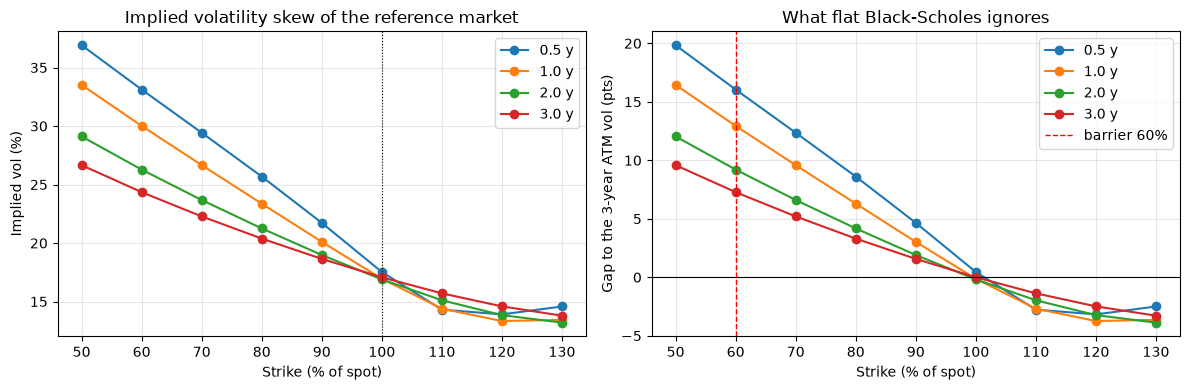

3-year implied vol at strike 60%: 24.35%   (ATM: 17.07%)
--> a gap of 7.3 volatility points at the protection barrier.


In [8]:
Ks = np.array([50, 60, 70, 80, 90, 100, 110, 120, 130.])
mats = [0.5, 1.0, 2.0, 3.0]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for Tm in mats:
    iv = [implied_vol(p, S0, K, Tm, r, q)
          for K, p in zip(Ks, heston_call(Ks, Tm, S0, r, q, HP))]
    ax[0].plot(Ks/S0*100, np.array(iv)*100, 'o-', label=f'{Tm} y')
ax[0].set(xlabel='Strike (% of spot)', ylabel='Implied vol (%)',
          title='Implied volatility skew of the reference market')
ax[0].axvline(100, color='k', lw=0.8, ls=':'); ax[0].legend()

for Tm in mats:
    iv = [implied_vol(p, S0, K, Tm, r, q)
          for K, p in zip(Ks, heston_call(Ks, Tm, S0, r, q, HP))]
    ax[1].plot(Ks/S0*100, np.array(iv)*100 - ATM*100, 'o-', label=f'{Tm} y')
ax[1].axhline(0, color='k', lw=0.8); ax[1].axvline(Bp*100, color='r', ls='--',
          lw=1, label=f'barrier {Bp:.0%}')
ax[1].set(xlabel='Strike (% of spot)', ylabel='Gap to the 3-year ATM vol (pts)',
          title='What flat Black-Scholes ignores'); ax[1].legend()
plt.tight_layout(); plt.show()

iv_Bp = implied_vol(heston_call([Bp*S0], T, S0, r, q, HP)[0], S0, Bp*S0, T, r, q)
print(f"3-year implied vol at strike {Bp:.0%}: {iv_Bp:.2%}   (ATM: {ATM:.2%})")
print(f"--> a gap of {(iv_Bp-ATM)*100:.1f} volatility points at the protection barrier.")

### Dupire local volatility (model M2) and the three Monte Carlo simulations
About 40 seconds. Same seeds as the course notebook, so the numbers are identical to the ones you get there.

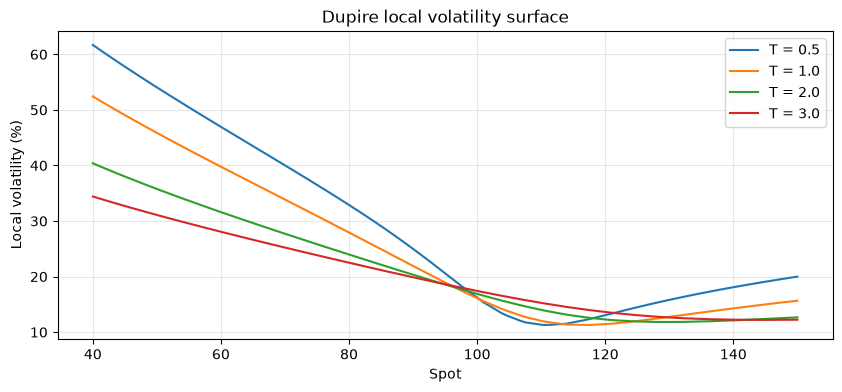

In [9]:
Ts_grid = np.linspace(0.05, 3.3, 40)
ys_grid = np.linspace(-1.1, 0.7, 61)
LV, W = build_local_vol(S0, r, q, HP, Ts_grid, ys_grid)

fig, ax = plt.subplots(figsize=(10, 4))
for Tm in [0.5, 1.0, 2.0, 3.0]:
    i = np.argmin(abs(Ts_grid - Tm)); F = S0*np.exp((r - q)*Tm)
    kk = np.linspace(40, 150, 120)
    ax.plot(kk, [np.sqrt(np.interp(np.log(k/F), ys_grid, LV.locvar[i]))*100 for k in kk],
            label=f'T = {Tm}')
ax.set(xlabel='Spot', ylabel='Local volatility (%)',
       title='Dupire local volatility surface'); ax.legend(); plt.show()

In [10]:
NPATH, NSTEP = 200_000, 750
OBS_IDX = np.round(OBS/T*NSTEP).astype(int)          # indices of the observation dates

sim_lv = simulate_localvol(S0, r, q, LV, T, NSTEP, NPATH, seed=7, obs_idx=OBS_IDX)    # M2
sim_h  = simulate_heston(S0, r, q, HP, T, NSTEP, NPATH, seed=11, obs_idx=OBS_IDX)     # M3 ("market")
sim_bs = simulate_bs(S0, r, q, ATM, T, NSTEP, NPATH, seed=11, obs_idx=OBS_IDX)        # M1
MODELS = {'M3 stochastic vol': sim_h, 'M2 local vol': sim_lv, 'M1 flat Black-Scholes': sim_bs}
print(f"Simulations ready: {NPATH:,} paths x {NSTEP} daily steps for M1, M2, M3.")

Simulations ready: 200,000 paths x 750 daily steps for M1, M2, M3.


In [11]:
# Helper used throughout the solutions: everything you want to know about a Phoenix on a set of paths
def phoenix_diagnostics(sim, american=False):
    ov, rm = sim; n = ov.shape[1]
    alive = np.ones(n, bool); knocked = np.zeros(n, bool); life = np.zeros(n)
    p_call, p_cpn = [], []
    for k, d in enumerate(OBS):
        perf = ov[k]/S0
        if american: knocked |= (rm[k]/S0 < Bp)
        p_cpn.append((alive & (perf >= Bc)).mean())
        if k < len(OBS) - 1:
            called = alive & (perf >= Ba)
            p_call.append(called.mean()); life[called] = d; alive &= ~called
        else:
            life[alive] = d
            ki = alive & (knocked if american else (perf < Bp))
            loss = np.where(ki, 1 - np.minimum(perf, 1.0), 0.0)
            out = dict(p_call=np.array(p_call), p_cpn=np.array(p_cpn), life=life.mean(),
                       p_alive_T=alive.mean(), p_loss=ki.mean(),
                       loss_given=loss[ki].mean() if ki.any() else 0.0, n_cpn=sum(p_cpn))
    return out

def blocks_with_ko(sim):
    # (ZC paid at tau, coupon annuity, put paid at T if alive): Phoenix = ZC + c*annuity - put
    ov, _ = sim; n = ov.shape[1]; alive = np.ones(n, bool)
    zc = np.zeros(n); ann = np.zeros(n); put = np.zeros(n)
    for k, d in enumerate(OBS):
        perf = ov[k]/S0; df = np.exp(-r*d)
        ann += np.where(alive & (perf >= Bc), df, 0.0)
        if k < len(OBS) - 1:
            called = alive & (perf >= Ba); zc += np.where(called, df, 0.0); alive &= ~called
        else:
            zc += np.where(alive, df, 0.0)
            put += np.where(alive & (perf < Bp), (1 - perf)*df, 0.0)
    return zc.mean(), ann.mean(), put.mean()
print("Helpers loaded.")

Helpers loaded.


---
# Part 1: Decomposing the payoff (Q1–Q5, ◆ individual)

## Q1 ◆ Cash flow on date $t_i$ and the four building blocks

**Question.** Write the cash flow on $t_i$ as a function of $S_{t_i}$ and of the survival indicator, then decompose the
Phoenix into a zero-coupon bond, a sold barrier put, a strip of bought digitals and a knock-out condition.

**Solution.** Write $A_i = \mathbf 1_{\{\text{not called before } t_i\}} = \prod_{j<i}\mathbf 1_{\{R_j < B_a\}}$ for the survival indicator. Per unit of notional:

* **Intermediate date** $t_i$, $i<n$:
$$CF_i = A_i\Big[\; c\,\mathbf 1_{\{R_i\ge B_c\}} \;+\; \mathbf 1_{\{R_i \ge B_a\}}\cdot 1 \;\Big]$$
(the coupon if the coupon barrier is met, and par if the autocall barrier is met).
* **Maturity** $t_n = T$:
$$CF_n = A_n\Big[\; c\,\mathbf 1_{\{R_n\ge B_c\}} \;+\; 1 \;-\; (1-R_n)\,\mathbf 1_{\{R_n<B_p\}}\;\Big]$$

From the investor's side, this splits into four building blocks:

| Block | Investor | Cash flow |
|---|---|---|
| **Zero-coupon bond** | long | pays 1 (par) at the redemption date $\tau$ |
| **Strip of digitals** (cash-or-nothing calls struck at $B_c$) | long | pays $c$ on each $t_i$ where $R_i \ge B_c$ |
| **European-barrier put** (strike 100 %, knock-in $B_p$ at $T$) | **short** | investor pays $(1-R_n)\,\mathbf 1_{\{R_n<B_p\}}$ |
| **Knock-out (autocall) condition** | — | on $t_i<T$, if $R_i\ge B_a$, **all the above stop** after that date's flows |

The issuer (the "seller" of the note) holds the opposite: short the ZC and the digital strip, long the put.

**Why it works.** The coupon is not interest. It is paid for by the put that the investor *sells*. The knock-out is not a
fifth asset. It is a condition that multiplies every other cash flow by $A_i$ (see Q3).

In [12]:
# Illustration: the cash flows on three hand-built paths (levels on the 6 dates, in % of S0)
def cashflows(levels, c=0.03):
    alive, out = True, []
    for k, (t, L) in enumerate(zip(OBS, levels)):
        R = L/100; cf = 0.0
        if alive:
            cf += c*(R >= Bc)
            if k < len(OBS) - 1:
                if R >= Ba: cf += 1.0; alive = False
            else:
                cf += 1.0 - (1 - R)*(R < Bp)
        out.append(cf)
    return out
for name, lv in [("rises: called at 1y", [95, 103, 120, 130, 125, 140]),
                 ("drifts sideways, never called", [90, 85, 92, 80, 88, 95]),
                 ("crash, knocked in at maturity", [90, 75, 60, 50, 48, 45])]:
    cf = cashflows(lv)
    print(f"{name:32s}", "  ".join(f"t={t:.1f}:{x:6.3f}" for t, x in zip(OBS, cf)),
          f"| total {sum(cf):.3f}")

rises: called at 1y              t=0.5: 0.030  t=1.0: 1.030  t=1.5: 0.000  t=2.0: 0.000  t=2.5: 0.000  t=3.0: 0.000 | total 1.060
drifts sideways, never called    t=0.5: 0.030  t=1.0: 0.030  t=1.5: 0.030  t=2.0: 0.030  t=2.5: 0.030  t=3.0: 1.030 | total 1.180
crash, knocked in at maturity    t=0.5: 0.030  t=1.0: 0.030  t=1.5: 0.000  t=2.0: 0.000  t=2.5: 0.000  t=3.0: 0.450 | total 0.510


## Q2 ◆ Justify the pricing formula (R1) term by term; which variables does the payoff depend on?

**Solution.** Under $\mathbb Q$ with deterministic $r$, the price is the expectation of the discounted cash flows from Q1:
$$V_0 = \mathbb E^{\mathbb Q}\Big[\sum_{i=1}^n e^{-rt_i}\,c\,\mathbf 1_{\{R_i\ge B_c\}}\mathbf 1_{\{t_i\le\tau\}} + e^{-r\tau}\,\Pi_\tau\Big].$$

* $\tau = \inf\{t_i,\ i<n : R_i\ge B_a\}$, with $\inf\emptyset = t_n$, is the **redemption date**. It is a stopping time because deciding
  whether $\tau = t_i$ only uses information up to $t_i$. The infimum is over $i<n$ only because at $t_n$ the note is redeemed anyway.
* $\mathbf 1_{\{R_i\ge B_c\}}$ is the **coupon condition** (the digital).
* $\mathbf 1_{\{t_i\le\tau\}}$ is the **survival** indicator $A_i$, *including* the call date. On the call date $R_i\ge B_a\ge B_c$, so
  the coupon of that date **is** paid. After $\tau$ nothing is paid.
* $e^{-r\tau}\Pi_\tau$ is the **redemption**, paid once at the random date $\tau$. If $\tau<t_n$ it is par ($\Pi=1$). If $\tau=t_n$ it is par minus the
  loss $(1-R_n)\mathbf 1_{\{R_n<B_p\}}$ (the European-barrier put).
* Writing $\sum_i e^{-rt_i}\mathbf 1_{\{\tau = t_i\}}\Pi_{t_i}$ for $e^{-r\tau}\Pi_\tau$ shows it is the sum of the Q1 flows. Linearity of
  the expectation does the rest.

**What it depends on.** The payoff is a function of the **whole vector** $(R_1,\dots,R_n) = (S_{t_1},\dots,S_{t_n})/S_0$:
$\tau$ depends on $R_1..R_{n-1}$, the coupons on every $R_i$, the loss on $R_n$. It is **not** a function of $S_T$ alone. Its
value therefore depends on the **joint law** of the spot on the six dates, and that is what will break the equivalence between models (Q10, Q12).
With a protection barrier observed at each close (Q14), it also depends on the **running minimum** of the path.

## Q3 ◆ Why the autocall clause is not a separable instrument; consequence for the expected life

**Solution.** A separable feature could be detached and traded alone, with its own cash flows, *without changing the rest
of the contract*. The autocall fails this test. It has no cash flow of its own: on the call date it pays par, which the ZC
would have paid at maturity anyway, and it **cancels every future cash flow**: the remaining coupons, the put, the redemption
at $T$. It is a condition $\mathbf 1_{\{t_i\le\tau\}}$ that multiplies **all** the other blocks. Each block becomes a
*knock-out* version of itself (a KO ZC, KO digitals, a KO put), and
$$V \;\neq\; V(\text{ZC}) + c\,V(\text{digitals}) - V(\text{put}) + V(\text{"autocall option"}).$$

**Consequence for the expected life.** The life of the note is the random variable $\tau$, and $\mathbb E[\tau]$ is far shorter
than 3 years because in a flat or rising market the note is very likely called at the first date. This means:
* the **duration** of the rate hedge and of the funding benefit is uncertain (it is the source of Part 7),
* the most likely scenario pays only **one or two coupons**,
* every greek of the product is a "knock-out" greek, discontinuous around $B_a$ on the observation dates (Q27).

The cell below measures it: expected life, call probabilities, and the error you make by pricing the blocks **as if** they were separable.

In [13]:
print("Expected life and call profile (reference market M3, European protection barrier)")
d3 = phoenix_diagnostics(sim_h)
print("  P(called at t_i):", "  ".join(f"{t:.1f}y:{p:5.1%}" for t, p in zip(OBS[:-1], d3['p_call'])))
print(f"  P(alive at maturity) = {d3['p_alive_T']:.1%}   P(loss at maturity) = {d3['p_loss']:.1%}"
      f"   average loss given loss = {d3['loss_given']:.1%}")
print(f"  Expected life E[tau] = {d3['life']:.2f} years (vs 3 years contractual)")
print(f"  Expected number of coupons = {d3['n_cpn']:.2f} (out of 6)")

# Separable (wrong) vs knock-out (right) decomposition under M3
zc_ko, ann_ko, put_ko = blocks_with_ko(sim_h)
zc_sep  = np.exp(-r*T)
ann_sep = sum(np.exp(-r*d)*(sim_h[0][k]/S0 >= Bc).mean() for k, d in enumerate(OBS))
put_sep = heston_european(lambda S: np.where(S/S0 < Bp, 1 - S/S0, 0.0), T, S0, r, q, HP)
c_ko  = (1 - zc_ko + put_ko)/ann_ko
c_sep = (1 - zc_sep + put_sep)/ann_sep
print("\n                       ZC       annuity    put     break-even coupon p.a.")
print(f"  knock-out blocks   {zc_ko:.4f}   {ann_ko:.4f}   {put_ko:.4f}   {2*c_ko:.3%}   <- correct (= Q12, M3)")
print(f"  'separable' blocks {zc_sep:.4f}   {ann_sep:.4f}   {put_sep:.4f}   {2*c_sep:.3%}   <- wrong")

Expected life and call profile (reference market M3, European protection barrier)
  P(called at t_i): 0.5y:59.2%  1.0y:10.2%  1.5y: 4.5%  2.0y: 2.8%  2.5y: 1.9%
  P(alive at maturity) = 21.5%   P(loss at maturity) = 6.2%   average loss given loss = 57.9%
  Expected life E[tau] = 1.21 years (vs 3 years contractual)
  Expected number of coupons = 1.99 (out of 6)

                       ZC       annuity    put     break-even coupon p.a.
  knock-out blocks   0.9762   1.9497   0.0336   5.882%   <- correct (= Q12, M3)
  'separable' blocks 0.9418   5.2016   0.0557   4.380%   <- wrong


**Reading the numbers (reference case, M3).** The note is called at the **first** date with probability **59 %**, and only
**21.5 %** of notes reach maturity. The expected life is **1.21 years** instead of 3, and the expected number of coupons is
**about 2 out of 6**. Pricing the blocks *as if* they were separable (a 3-year ZC, 6 independent digitals, the full European put)
gives **4.38 %** instead of **5.88 %**: the annuity is overstated by a factor of 2.7 (5.20 vs 1.95) and the put by 65 %. You
cannot price the autocall "on the side".

## Q4 ◆ The structuring equation

**Solution.** At issue the investor pays par (100 %). The bank must cover everything it gives and keep its margin and fees:
$$\underbrace{1}_{\text{par}} \;=\; \underbrace{ZC^{\text{issuer}}}_{\text{redemption at }\tau}\;+\;\underbrace{c\cdot A}_{\text{digital strip}}\;-\;\underbrace{P}_{\text{put premium}}\;+\;\underbrace{M}_{\text{structuring margin}}\;+\;\underbrace{D}_{\text{distribution fee}}$$
where $A$ is the annuity of the (knock-out) digital strip and $ZC^{\text{issuer}} = ZC^{\text{risk-free}} - FB$ is the zero-coupon
discounted on the issuer's credit curve. $FB$ is the **funding benefit**: the bank borrows at its own spread.

Solving for the coupon:
$$\boxed{\;c\cdot A \;=\; \underbrace{\big(1-ZC^{\text{rf}}\big)}_{\text{interest over the expected life}} \;+\; \underbrace{P}_{\text{put sold by the investor}} \;+\; \underbrace{FB}_{\text{funding}} \;-\; M \;-\; D\;}$$

**Why it matters.** The coupon budget comes from three sources: rates, the put premium (driven by volatility and skew at $B_p$)
and the issuer's spread. Margin and fees come out of it. A short expected life shrinks *both* the interest term and the funding
term, which is one reason why early redemption is costly for the investor.

## Q5 ◆ European-barrier put vs American down-and-in put

**Solution.**
* **European barrier** (observed at maturity only): payoff $(1-R_T)\,\mathbf 1_{\{R_T < B_p\}}$. This is a **function of $S_T$ only**:
  a put struck at $B_p$ plus $(1-B_p)$ digital puts at $B_p$, so it decomposes into vanillas.
* **American down-and-in** (continuous, or at each close): payoff $(1-R_T)^+\,\mathbf 1_{\{\min_{t\le T}R_t < B_p\}}$. Once the barrier has been
  touched at any time, the investor bears the whole downside at $T$, even if the market partly recovered.

On every path $\mathbf 1_{\{R_T<B_p\}} \le \mathbf 1_{\{\min R_t<B_p\}}$, and when $R_T<B_p$ the two losses are equal. So the American payoff dominates
pathwise and **the American DIP is more expensive**. The investor who sells it receives a bigger premium and gets a higher coupon.

**Why the market switched to European after 2008.** In 2008 many American-barrier notes knocked in on a daily or intraday touch.
Investors then lost capital even when the index recovered by maturity, which caused disputes, mis-selling cases and regulatory
pressure on complexity and transparency (MiFID, national regulators). A barrier observed only at maturity is easier to explain
("you lose only if the market is down more than 40 % *at maturity*") and has less path dependence. For the issuer it also
concentrates the barrier gap risk on the final date instead of spreading it over the whole life (Q25). Lower rates also
pushed the market towards products whose risk is easier to explain.

In [14]:
# How much more expensive is the American (daily-close) down-and-in put?  Standalone puts, no autocall.
print(f"Standalone put, strike 100%, barrier {Bp:.0%}, T = 3y   ({NPATH:,} paths, {NSTEP} daily closes)")
for name, sim in MODELS.items():
    ov, rm = sim; RT = ov[-1]/S0; mn = rm.min(axis=0)/S0
    eu = np.exp(-r*T)*np.where(RT < Bp, 1 - RT, 0.0)
    am = np.exp(-r*T)*np.where(mn < Bp, np.maximum(1 - RT, 0.0), 0.0)
    print(f"  {name:24s} European {eu.mean():7.3%} (SE {mc_se(eu):.3%})   "
          f"daily-close {am.mean():7.3%} (SE {mc_se(am):.3%})   ratio {am.mean()/eu.mean():.2f}")

Standalone put, strike 100%, barrier 60%, T = 3y   (200,000 paths, 750 daily closes)
  M3 stochastic vol        European  5.596% (SE 0.036%)   daily-close  7.894% (SE 0.037%)   ratio 1.41
  M2 local vol             European  5.481% (SE 0.035%)   daily-close  7.401% (SE 0.036%)   ratio 1.35
  M1 flat Black-Scholes    European  2.513% (SE 0.022%)   daily-close  3.927% (SE 0.025%)   ratio 1.56


---
# Part 2: Taxonomy of model risk and decision ladder (Q6–Q9, ◆ individual)

## Q6 ◆ One Phoenix example for each form of model risk

| Form | Concrete Phoenix example |
|---|---|
| **(i) Badly implemented** | the autocall test also applied at maturity, so a note at 105 % at $T$ is "called" and redeemed twice; the coupon of the call date forgotten; the coupon treated as annual instead of semi-annual; Euler scheme without the Itô term (the spot is not a martingale); observation dates off by one grid step; barriers rescaled by the *bumped* spot when computing delta. All of these are tested in Block D. |
| **(ii) Correct model, bad inputs** | 3-year dividends on a single stock (sets the forward, hence every barrier probability); a stale or badly extrapolated implied vol at the 60 % strike (the put moves by a factor of two between 17 % and 24 % vol, see Q11); wrong issuer funding spread; wrong repo. |
| **(iii) Wrong model for the product** | pricing the Phoenix in flat Black–Scholes at the ATM vol (ignores the skew: Q12 gives about 195 bp of coupon too low); or in local volatility, which is perfectly calibrated but has the **wrong forward skew**: about +106 bp versus stochastic vol (Q12, Q16). |

The point of the TD: (iii) can be large **even with perfect calibration and perfect code**.

## Q7 ◆ The decision ladder (A: vanillas + BS, B: local vol, C: stochastic vol)

| Payoff | Level | One-sentence justification |
|---|---|---|
| (a) Call spread | **A** | It is literally two vanillas. Each is priced with its own implied vol, so it is model-free given the smile. |
| (b) Asian option | **B** | Path-dependent through the average, so it cannot be decomposed into vanillas. It depends on the skew and the term structure, and a well-calibrated local vol captures it reasonably (low vega convexity). |
| (c) European digital | **A** | It is the limit of a tight call spread, $-\partial C/\partial K$: priced from vanillas, provided you use the skew (BS with the *slope* of the smile, not just one vol). |
| (d) European-barrier put | **A** | A function of $S_T$ only: a put at $B_p$ plus $(1-B_p)$ digital puts. Static replication with vanillas. |
| (e) Down-and-in put, continuous barrier | **B** | Path-dependent (running minimum), so it cannot be decomposed. Its value is driven by the skew near the barrier, and local vol is the market minimum (with some residual vol-of-vol sensitivity). |
| (f) Cliquet with local floors and caps | **C** | A sum of forward-starting call spreads: its value is the **forward skew**, which local vol flattens. You need stochastic vol. |
| (g) Full Phoenix | **C** | After every non-call date the remaining product is a forward-starting structure (Q16). It has vega convexity around the barriers and its value depends on the forward skew: 106 bp gap between M2 and M3 in Q12. |

## Q8 ◆ Why a call spread can be priced in Black–Scholes, and why the Phoenix cannot

**Solution.** A call spread is $C(K_1)-C(K_2)$. Each leg is a quoted vanilla, and Black–Scholes is only used as a
**quotation device**: a one-to-one map between a price and *its* implied vol. Plugging in $\sigma_{\text{imp}}(K_1)$ and
$\sigma_{\text{imp}}(K_2)$ reproduces market prices exactly. The skew is "in the inputs", the replication is **static** and
**no dynamics** is needed.

The Phoenix has no such static replication. The autocall makes every cash flow conditional on the path. Its value depends on
the joint law of $(S_{t_1},\dots,S_{t_n})$, so there is no set of vanillas whose prices pin it down, and there is no
"right" implied vol to plug into BS. A single $\sigma$ (or one $\sigma$ per strike) does not define a dynamics, and the dynamics
is exactly what the product is sensitive to.

## Q9 ◆ Completeness of M1, M2, M3 when hedging with the underlying alone

**Solution (R5).** Count the Brownian motions $d$ and the traded risky assets besides cash:

| Model | Brownian motions | Traded assets | Volatility matrix | Market |
|---|---|---|---|---|
| M1 Black–Scholes | 1 ($W$) | 1 ($S$) | $1\times1$: $\sigma_{ATM}S \neq 0$, invertible | **complete** |
| M2 local vol | 1 ($W$) | 1 ($S$) | $1\times1$: $\sigma_{loc}(S,t)S > 0$ (floored), invertible | **complete** |
| M3 Heston | 2 ($W^1, W^2$, or independent $W^1, W^\perp$) | 1 ($S$) | $1\times2$, not square, so not invertible | **incomplete** |

In M3, the variance $v$ is a risk factor that is **not traded**. There are infinitely many martingale measures, indexed by the
market price of volatility risk.

**In practice.** Under M3 a delta hedge with the underlying alone **cannot** reduce the P&L to zero, even with continuous
rebalancing. The part of the vol moves orthogonal to spot, a share $\sqrt{1-\rho^2}\approx 71\,\%$ of the vol-of-vol noise, stays
unhedged. The residual P&L is of order *vega × vol of vol*. The best you can do with the underlying is a **minimum-variance**
delta (Q24).

**Adding vanillas.** One vanilla with non-zero vega (sensitivity to $v$) gives 2 traded assets for 2 Brownian motions, and the
$2\times2$ volatility matrix $\begin{pmatrix} S\sqrt v & 0\\ C_S S\sqrt v + C_v\xi\sqrt v\rho & C_v\xi\sqrt v\sqrt{1-\rho^2}\end{pmatrix}$ is invertible
when $C_v\neq0$. The market becomes **complete within the model**. You can then hedge delta *and* vega, and the residual comes
only from discrete rebalancing, jumps or gaps, and from the model being wrong. Q24 runs exactly this experiment.

---
# Part 3: Calibration *is* a model choice (Q10–Q18)

## Q10 ● Gyöngy: M2 and M3 agree on every $g(S_T)$, but not on $g(S_{T_1},S_{T_2})$

**Proof.** Dupire's local vol is built from the implied vol surface generated by M3, which is equivalent to
$\sigma^2_{loc}(K,T) = \mathbb E^{M3}[v_T\mid S_T=K]$ (the Dupire–Gyöngy identity). By Gyöngy (R4), the local vol process
$\tilde S$ (M2) has, **for each $T$**, the same marginal law as $S_T$ under M3. For a payoff $g(S_T)$ with deterministic discounting:
$$V^{M2} = e^{-rT}\,\mathbb E[g(\tilde S_T)] = e^{-rT}\int g(s)\,p_T(s)\,ds = e^{-rT}\,\mathbb E[g(S_T)] = V^{M3},$$
because only the marginal density $p_T$ enters. ∎

**Why it does not extend.** For $g(S_{T_1},S_{T_2})$:
$$\mathbb E[g(S_{T_1},S_{T_2})] = \iint g(x,y)\;p_{T_1}(x)\;\underbrace{p(T_1,x;\,T_2,y)}_{\textbf{transition kernel}}\,dx\,dy.$$
Gyöngy matches $p_{T_1}$ and $p_{T_2}$, but says nothing about the **transition kernel** (equivalently the copula between dates).
That object is what the **forward smile** (R6) measures, and vanillas do not constrain it. Two models with identical vanillas can
therefore disagree on any path-dependent payoff.

**Numerical check (notebook §1–2).** The cell below adds the Monte Carlo standard errors and a martingale check to the
course table.

In [15]:
# --- Validation: does local vol reproduce the market's vanillas?
ST = sim_lv[0][-1]                                    # spot at maturity

print(f"Local vol Monte Carlo: {NPATH:,} paths, {NSTEP} time steps (one per trading day)\n")
print(f"{'Strike':>7} {'Market (ref.)':>14} {'Local vol MC':>14} {'diff':>9}"
      f" {'IV ref.':>9} {'IV loc.':>9}")
for K in [60, 70, 80, 90, 100, 110, 120]:
    ref = heston_call([K], T, S0, r, q, HP)[0]
    mc  = np.exp(-r*T)*np.maximum(ST - K, 0).mean()
    print(f"{K:7.0f} {ref:14.4f} {mc:14.4f} {mc-ref:+9.4f}"
          f" {implied_vol(ref,S0,K,T,r,q):9.4f} {implied_vol(mc,S0,K,T,r,q):9.4f}")

Local vol Monte Carlo: 200,000 paths, 750 time steps (one per trading day)

 Strike  Market (ref.)   Local vol MC      diff   IV ref.   IV loc.


     60        39.3325        39.2859   -0.0466    0.2435    0.2415


     70        31.1385        31.0839   -0.0546    0.2228    0.2212


     80        23.5541        23.4964   -0.0576    0.2038    0.2026


     90        16.7858        16.7309   -0.0549    0.1865    0.1855


    100        11.0709        11.0232   -0.0477    0.1707    0.1700


    110         6.6324         6.6048   -0.0276    0.1570    0.1566


    120         3.5741         3.5640   -0.0100    0.1459    0.1457


In [16]:
# Solutions add-on: standard errors and martingale test for the local vol check
ST_lv = sim_lv[0][-1]
print(f"{'K':>5} {'MC - ref':>9} {'SE':>7} {'z = diff/SE':>12} {'IV gap (vol pts)':>17}")
for K in [60, 70, 80, 90, 100, 110, 120]:
    ref = heston_call([K], T, S0, r, q, HP)[0]
    pay = np.exp(-r*T)*np.maximum(ST_lv - K, 0)
    print(f"{K:5.0f} {pay.mean()-ref:+9.4f} {mc_se(pay):7.4f} {(pay.mean()-ref)/mc_se(pay):+12.1f}"
          f" {100*(implied_vol(pay.mean(),S0,K,T,r,q)-implied_vol(ref,S0,K,T,r,q)):+17.2f}")
mart = sim_lv[0]*np.exp(-(r - q)*OBS)[:, None]
print("\nMartingale test E[S_t e^{-(r-q)t}] - S0 on each date (should be 0):")
print("  " + "  ".join(f"t={t:.1f}: {m.mean()-S0:+.3f} (SE {mc_se(m):.3f})" for t, m in zip(OBS, mart)))

    K  MC - ref      SE  z = diff/SE  IV gap (vol pts)


   60   -0.0466  0.0135         -3.5             -0.20


   70   -0.0546  0.0148         -3.7             -0.16


   80   -0.0576  0.0175         -3.3             -0.12


   90   -0.0549  0.0208         -2.6             -0.10


  100   -0.0477  0.0232         -2.1             -0.07


  110   -0.0276  0.0221         -1.2             -0.04


  120   -0.0100  0.0182         -0.6             -0.02

Martingale test E[S_t e^{-(r-q)t}] - S0 on each date (should be 0):
  t=0.5: -0.012 (SE 0.009)  t=1.0: -0.004 (SE 0.012)  t=1.5: +0.005 (SE 0.013)  t=2.0: -0.000 (SE 0.014)  t=2.5: +0.005 (SE 0.015)  t=3.0: +0.005 (SE 0.015)


**Reading (reference case, 200,000 paths, 750 steps).** The local vol Monte Carlo reprices the market calls within **0.01 to
0.06 of a price point**, i.e. **0.02 to 0.20 vol points**. The gaps all have the **same sign** (local vol slightly low), and at low
strikes they reach **3 to 3.7 standard errors**. This is not Monte Carlo noise but a small **systematic numerical bias** of
the Dupire surface: finite-difference derivatives on a 40 × 61 grid, piecewise-constant local vol in time, the floor and cap,
and the time-stepping. It is largest in the low strikes, where the put lives (Q11). The martingale test passes on every date
(|z| < 1.4), so the scheme itself is fine. Conclusion: **Gyöngy holds up to a numerical error of about 0.1–0.2 vol point**. It
guarantees that every *marginal* law $S_T$ is equal, hence every European price, and says **nothing** about joint laws.

## Q11 ● The European-barrier put alone under M1, M2, M3

In [17]:
dip = lambda S: np.where(S/S0 < Bp, np.maximum(1 - S/S0, 0.0), 0.0)


dip_prices = {
    'M3 stochastic vol (market)': heston_european(dip, T, S0, r, q, HP),
    'M2 local vol (Dupire)'     : np.exp(-r*T)*dip(sim_lv[0][-1]).mean(),
    'M1 flat Black-Scholes'     : np.exp(-r*T)*dip(sim_bs[0][-1]).mean(),
}
dip_se = {                                   # Monte Carlo standard errors (None: semi-analytic)
    'M3 stochastic vol (market)': None,
    'M2 local vol (Dupire)'     : np.exp(-r*T)*mc_se(dip(sim_lv[0][-1])),
    'M1 flat Black-Scholes'     : np.exp(-r*T)*mc_se(dip(sim_bs[0][-1])),
}
ref = dip_prices['M3 stochastic vol (market)']
print(f"European-barrier put (K=100%, H={Bp:.0%}, T=3 y), in % of notional")
print(f"M2 and M1: Monte Carlo, {NPATH:,} paths ({NPATH//2:,} antithetic pairs), {NSTEP} time steps."
      f"\nM3: semi-analytic (COS method), no Monte Carlo error.\n")
print(f"  {'Model':28s} {'price':>8s} {'std error':>14s}   {'gap vs market':>13s}")
for k, v in dip_prices.items():
    se = dip_se[k]
    se_txt = 'semi-analytic' if se is None else f"{se:.4%}"
    gap_se = '' if se is None else f"  (SE {se/ref:.1%})"
    print(f"  {k:28s} {v:8.4%} {se_txt:>14s}   {v/ref-1:+13.1%}{gap_se}")

European-barrier put (K=100%, H=60%, T=3 y), in % of notional
M2 and M1: Monte Carlo, 200,000 paths (100,000 antithetic pairs), 750 time steps.
M3: semi-analytic (COS method), no Monte Carlo error.

  Model                           price      std error   gap vs market
  M3 stochastic vol (market)    5.5689%  semi-analytic           +0.0%
  M2 local vol (Dupire)         5.4811%        0.0352%           -1.6%  (SE 0.6%)
  M1 flat Black-Scholes         2.5132%        0.0223%          -54.9%  (SE 0.4%)


**Solution (reference case, 200,000 paths, 750 steps).**

| Model | Price | SE | Gap vs M3 |
|---|---|---|---|
| M3 stochastic vol (market) | 5.569 % | semi-analytic | — |
| M2 local vol | 5.481 % | 0.035 % | −1.6 % (≈ 2.5 SE) |
| M1 flat BS at ATM vol | 2.513 % | 0.022 % | **−55 %** |

* **M2 vs M3**: practically equal, as Gyöngy predicts, since the payoff depends on $S_T$ only. The small residual of
  −0.09 point (−1.6 %) has the same sign and size as the vanilla bias of Q10. It is the **numerical** Dupire error at low strikes, not model risk.
* **M1 vs M3**: the price is **divided by two**. Flat BS uses 17.07 %, while the market's implied vol at the 60 % strike is
  24.35 %: 7.3 vol points of skew are ignored exactly where the put pays.

**Conclusion.** For a payoff that depends on $S_T$ only, the *dynamics* do not matter. Any model calibrated to the whole smile
gives the same price, so model risk is about zero. What matters is **calibration to the right strikes**. M1's failure is an
input/calibration error (wrong vol for the strike, form (ii)/(iii)), not a subtle dynamics problem.

## Q12 ● The full Phoenix under the three models: break-even coupons

Recall: $c = (1-\text{redemption leg})/\text{annuity}$, quoted per year as $2c$. The gap is in bp of annual coupon.

In [18]:
def coupon_table(american):
    # returns (break-even semi-annual coupons, their standard errors), one entry per model
    print(f"{'Model':24s} {'coupon/half-yr':>14s} {'coupon p.a.':>12s} {'SE p.a.':>9s}"
          f" {'annuity':>9s} {'redemption':>11s}")
    res, se = {}, {}
    for name, p in MODELS.items():
        _, ann, red = phoenix_mc(p, S0, r, OBS, Ba, Bc, 1.0, Bp, american=american)
        c = break_even_coupon(ann, red); res[name] = c
        se[name] = break_even_coupon_se(*phoenix_paths(p, S0, r, OBS, Ba, Bc, Bp,
                                                       american=american))[1]
        print(f"{name:24s} {c:14.3%} {2*c:12.3%} {2*se[name]*1e4:6.1f} bp"
              f" {ann:9.4f} {red:11.4f}")
    return res, se

print(f"Monte Carlo: {NPATH:,} paths per model ({NPATH//2:,} antithetic pairs), {NSTEP} time steps."
      f"\nSE p.a. = standard error of the annual coupon (delta method), in bp.\n")
print("=== EUROPEAN protection barrier (observed at maturity) ===")
res_eu, se_eu = coupon_table(False)
print("\n=== DAILY-CLOSE protection barrier (observed at each close) ===")
res_daily, se_daily = coupon_table(True)

for lab, res, se in [("European", res_eu, se_eu), ("daily-close", res_daily, se_daily)]:
    gap    = (res['M2 local vol'] - res['M3 stochastic vol'])*2*1e4
    se_gap = np.hypot(se['M2 local vol'], se['M3 stochastic vol'])*2*1e4
    print(f"\n{lab:11s} barrier: local vol / stochastic vol gap = {gap:+.0f} bp of annual coupon"
          f"  (SE {se_gap:.1f} bp)")

Monte Carlo: 200,000 paths per model (100,000 antithetic pairs), 750 time steps.
SE p.a. = standard error of the annual coupon (delta method), in bp.

=== EUROPEAN protection barrier (observed at maturity) ===
Model                    coupon/half-yr  coupon p.a.   SE p.a.   annuity  redemption
M3 stochastic vol                2.941%       5.882%    3.4 bp    1.9497      0.9427
M2 local vol                     3.473%       6.946%    3.9 bp    1.8438      0.9360


M1 flat Black-Scholes            1.965%       3.931%    1.8 bp    2.4561      0.9517

=== DAILY-CLOSE protection barrier (observed at each close) ===
Model                    coupon/half-yr  coupon p.a.   SE p.a.   annuity  redemption
M3 stochastic vol                3.629%       7.258%    3.6 bp    1.9497      0.9292
M2 local vol                     4.151%       8.302%    4.1 bp    1.8438      0.9235
M1 flat Black-Scholes            2.415%       4.831%    2.1 bp    2.4561      0.9407

European    barrier: local vol / stochastic vol gap = +106 bp of annual coupon  (SE 5.2 bp)

daily-close barrier: local vol / stochastic vol gap = +104 bp of annual coupon  (SE 5.5 bp)


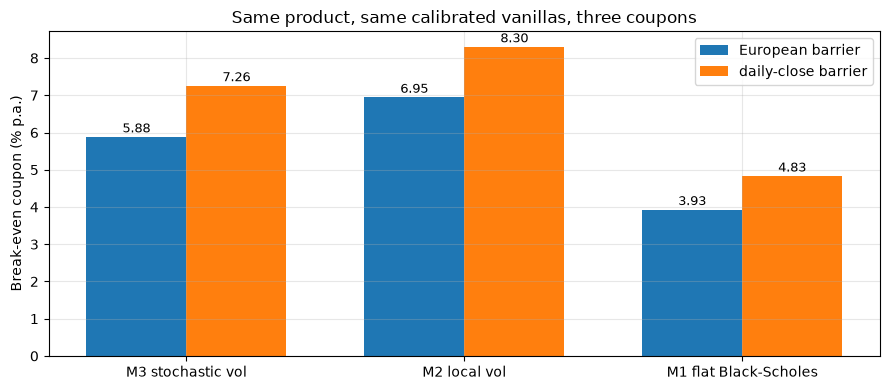

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
names = list(MODELS); x = np.arange(len(names)); wdt = 0.36
ax.bar(x - wdt/2, [res_eu[n]*200 for n in names], wdt, label='European barrier')
ax.bar(x + wdt/2, [res_daily[n]*200 for n in names], wdt, label='daily-close barrier')
ax.set_xticks(x); ax.set_xticklabels(names)
ax.set_ylabel("Break-even coupon (% p.a.)")
ax.set_title("Same product, same calibrated vanillas, three coupons")
for i, n in enumerate(names):
    ax.text(i - wdt/2, res_eu[n]*200 + .12, f"{res_eu[n]*200:.2f}", ha='center', fontsize=9)
    ax.text(i + wdt/2, res_daily[n]*200 + .12, f"{res_daily[n]*200:.2f}", ha='center', fontsize=9)
ax.legend(); plt.tight_layout(); plt.show()

**Solution (reference case; 200,000 paths per model, 750 steps, SE by the delta method on antithetic pairs).**

| Model | Coupon p.a. | SE | Annuity | Redemption leg |
|---|---|---|---|---|
| M3 stochastic vol | **5.88 %** | 3.4 bp | 1.950 | 0.943 |
| M2 local vol | **6.95 %** | 3.9 bp | 1.844 | 0.936 |
| M1 flat BS | 3.93 % | 1.8 bp | 2.456 | 0.952 |

**M2 − M3 gap = +106 bp of annual coupon, SE 5.2 bp**, so about 20 standard errors: certainly not Monte Carlo noise.
The three models see the **same vanillas** (M2 and M3 exactly), yet give coupons 300 bp apart. M1 is far below because its put is
half price (Q11), so the investor's "budget" is too small. M2 is **above** M3 even though the put alone was identical.

## Q13 ● Where does the M2/M3 gap come from? Two channels

**Solution.** The only thing that changed between Q11 (gap ≈ 0) and Q12 (gap ≈ 106 bp) is the **autocall clause**. It makes
the payoff depend on the spot on **several dates**, hence on the transition law between dates, which Gyöngy does not
constrain (Q10). It acts through two channels:

**(a) What the product becomes after a non-call date.** If $R_i < B_a$ at $t_i$, the holder now has a **new Phoenix starting
at $t_i$**, with a shorter maturity, struck relative to $S_0$ while the spot is somewhere below 100 %. Its value is that of
*forward-starting* digitals (the coupons at $B_c$) and a forward-starting put (at $B_p$), all seen from $t_i$. It is priced by
the **forward smile** $t_i\to t_j$, which differs between M2 and M3 (Q16).

**(b) Call probabilities, hence expected life.** The probability of being called on each date, and of being above $B_c$ while
alive, depends on the *joint* law of $(S_{t_1},\dots,S_{t_n})$. The annuities differ: **1.950 (M3) vs 1.844 (M2)**. Under local
vol, fewer coupons are expected, so each coupon must be bigger to reach par. This channel accounts for most of the gap.
The cell below breaks it down date by date.

In [20]:
print("Date-by-date profile of the Phoenix (European protection barrier)")
diag = {n: phoenix_diagnostics(s) for n, s in MODELS.items()}
print(f"{'':24s}" + "".join(f"{f't={t:.1f}':>8s}" for t in OBS))
for n, d in diag.items():
    print(f"{n[:22]:22s} call " + "".join(f"{p:8.1%}" for p in d['p_call']) + f"{'':8s}")
for n, d in diag.items():
    print(f"{n[:22]:22s} cpn  " + "".join(f"{p:8.1%}" for p in d['p_cpn']))
print(f"\n{'':24s}{'E[life]':>9s} {'E[#coupons]':>12s} {'P(alive T)':>11s} {'P(loss)':>8s} {'loss|loss':>10s}")
for n, d in diag.items():
    print(f"{n:24s}{d['life']:8.2f}y {d['n_cpn']:12.2f} {d['p_alive_T']:11.1%} {d['p_loss']:8.2%}"
          f" {d['loss_given']:10.1%}")

# Attribution of the M2-M3 coupon gap: c = (1 - red)/ann  ->  swap one leg at a time
ann = {n: phoenix_mc(s, S0, r, OBS, Ba, Bc, 1.0, Bp)[1] for n, s in MODELS.items()}
red = {n: phoenix_mc(s, S0, r, OBS, Ba, Bc, 1.0, Bp)[2] for n, s in MODELS.items()}
m2, m3 = 'M2 local vol', 'M3 stochastic vol'
c33, c23 = (1-red[m3])/ann[m3], (1-red[m2])/ann[m3]
c22 = (1-red[m2])/ann[m2]
print(f"\nAttribution of the gap ({2e4*(c22-c33):.0f} bp p.a.):")
print(f"  redemption leg M3 -> M2 (annuity of M3 kept): {2e4*(c23-c33):+5.0f} bp")
print(f"  annuity        M3 -> M2                     : {2e4*(c22-c23):+5.0f} bp")

Date-by-date profile of the Phoenix (European protection barrier)
                           t=0.5   t=1.0   t=1.5   t=2.0   t=2.5   t=3.0
M3 stochastic vol      call    59.2%   10.2%    4.5%    2.8%    1.9%        
M2 local vol           call    58.5%   11.9%    5.4%    3.1%    2.0%        
M1 flat Black-Scholes  call    47.6%   12.0%    5.9%    3.7%    2.6%        
M3 stochastic vol      cpn     96.6%   34.5%   23.1%   18.0%   14.8%   12.5%
M2 local vol           cpn     96.8%   35.0%   21.3%   14.9%   11.3%    9.0%
M1 flat Black-Scholes  cpn     99.8%   50.1%   35.3%   27.1%   21.7%   17.7%

                          E[life]  E[#coupons]  P(alive T)  P(loss)  loss|loss
M3 stochastic vol           1.21y         1.99       21.5%    6.16%      57.9%
M2 local vol                1.18y         1.88       19.1%    7.42%      58.6%
M1 flat Black-Scholes       1.43y         2.52       28.2%    4.57%      47.1%

Attribution of the gap (106 bp p.a.):
  redemption leg M3 -> M2 (annuity of M3 ke

**Reading (reference case).**

| | M3 | M2 | |
|---|---|---|---|
| called at 0.5y | 59.2 % | 58.5 % | almost the same: the **first** date is a 6-month vanilla-like event |
| called later (1y → 2.5y) | 19.4 % | 22.4 % | LV calls **more** of the survivors later |
| coupon probability at 2y / 2.5y / 3y | 18.0 / 14.8 / 12.5 % | 14.9 / 11.3 / 9.0 % | LV pays **fewer** coupons to the survivors |
| P(loss at maturity) | 6.2 % | 7.4 % | LV loses capital **more** often |
| expected life | 1.21 y | 1.18 y | |

**Attribution of the 106 bp:** the **redemption leg accounts for about +69 bp** and the **annuity for about +38 bp**.

* **Channel (a), what the product becomes after a non-call date: the larger part.** The survivors (spot below 100 % after a date) hold a
  forward-starting Phoenix. Under local vol their future is **more dispersed**: more of them are called later, more of them end
  below $B_p$ (P(loss) 7.4 % vs 6.2 %), and fewer stay in the middle zone $[B_c, B_a)$. The forward put the investor is short is
  therefore worth more, and the redemption leg falls (0.936 vs 0.943).
* **Channel (b), call probabilities, coupons and expected life.** The same dispersion empties the "coupon but no call" zone, so the
  annuity drops from 1.950 to 1.844 coupons-equivalent: −0.11 expected coupons, each to be paid for by a higher coupon.

Both channels come from **the same object**: the law of the *next* moves seen from an intermediate date, i.e. the forward smile.
Local vol has a **higher forward ATM vol (17.8 % vs 16.5 %) and a flatter forward skew** (Q16), which spreads the survivors out in both
directions. Calibration cannot see it because every *marginal* law is identical.

## Q14 ● Protection barrier observed at each close

**Solution (reference case, same paths, 750 daily closes).**

| | European barrier | Daily-close barrier | Change |
|---|---|---|---|
| M3 | 5.88 % | 7.26 % | **+138 bp** |
| M2 | 6.95 % | 8.30 % | **+136 bp** |
| M1 | 3.93 % | 4.83 % | +90 bp |
| **M2 − M3 gap** | **+106 bp** (SE 5.2) | **+104 bp** (SE 5.5) | no significant change |

* The coupon rises by about **140 bp**. The investor sells a more valuable put (Q5: knock-in on any close below $B_p$), so the
  budget grows. The annuity is unchanged because the coupon and call legs do not depend on the protection barrier. Only the
  redemption leg drops (0.943 → 0.929 under M3).
* **The M2–M3 gap does not widen** in the reference case (106 vs 104 bp, within one SE). The forward-skew mechanism
  of Q13 is still there and the barrier does not amplify it much here. Depending on your term sheet you may see a few bp of
  difference either way. Always judge it against the SE of the gap.
* **Calibration required.** The European-barrier put only needs the **3-year slice** of the smile at low strikes. A put that
  can knock in **any day** is sensitive to the volatility at **every maturity** from today to 3 years, around the barrier
  level: its vega is **spread over time** (see the vega buckets below). So the product needs a calibration that is
  **smooth and accurate over the whole surface** (strikes and maturities), not just exact at maturity. Any kink or arbitrage in
  the intermediate maturities leaks into the price.
* **The term sheet must specify** the barrier observation exactly: closing price vs intraday, which exchange / official close,
  every trading day vs specific dates, the treatment of market disruption days, strict vs non-strict inequality
  ($<$ vs $\le$), and the barrier level in % of which initial fixing.

In [21]:
# Solutions add-on: where is the vega of each put? Implied-vol PILLAR buckets (1y, 2y, 3y), local vol M2.
# Pillar p gets +1 vol pt of implied vol with a hat weight in maturity (the three weights sum to 1), LOCALISED in strike
# around the barrier (Gaussian in y = ln(K/F), centred on ln(Bp), width 0.15): "the smile near the barrier at maturity p".
IV0 = np.sqrt(W/Ts_grid[:, None])
def lv_from_w(w): return LocalVolSurface(ys_grid, Ts_grid, w)
def hat(p, Tm):
    if p == 1: return np.clip(2 - Tm, 0, 1)
    if p == 2: return np.clip(1 - abs(Tm - 2), 0, 1)
    return np.clip(Tm - 2, 0, 1)
NPB, NSB = 100_000, 750
base = simulate_localvol(S0, r, q, LV, T, NSB, NPB, seed=5, obs_idx=OBS_IDX)
def put_values(sim):
    ov, rm = sim; RT = ov[-1]/S0; mn = rm.min(axis=0)/S0
    eu = np.exp(-r*T)*np.where(RT < Bp, 1 - RT, 0.0).mean()
    am = np.exp(-r*T)*np.where(mn < Bp, np.maximum(1 - RT, 0.0), 0.0).mean()
    return eu, am
eu0, am0 = put_values(base)
print(f"Vega by implied-vol pillar (+1 vol pt), local vol, {NPB:,} paths, same seed, in % of notional")
print(f"{'pillar':>8s} {'European put':>14s} {'daily-close put':>16s}")
tot = np.zeros(2)
gauss = np.exp(-0.5*((ys_grid[None, :] - np.log(Bp))/0.15)**2)
for p in (1, 2, 3):
    lvb = lv_from_w((IV0 + 0.01*hat(p, Ts_grid)[:, None]*gauss)**2*Ts_grid[:, None])
    eu1, am1 = put_values(simulate_localvol(S0, r, q, lvb, T, NSB, NPB, seed=5, obs_idx=OBS_IDX))
    tot += [eu1 - eu0, am1 - am0]
    print(f"{f'{p}y':>8s} {100*(eu1-eu0):+13.3f}% {100*(am1-am0):+15.3f}%")
print(f"{'total':>8s} {100*tot[0]:+13.3f}% {100*tot[1]:+15.3f}%")

Vega by implied-vol pillar (+1 vol pt), local vol, 100,000 paths, same seed, in % of notional
  pillar   European put  daily-close put


      1y        +0.004%          -0.034%


      2y        -0.002%          -0.169%


      3y        +0.651%          +0.348%
   total        +0.652%          +0.146%


**Reading (reference case).** We bump the implied vol **near the barrier strike** at one maturity pillar at a time:
* **European put**: essentially all its vega is on the **3-year** pillar (+0.65 % of notional). The 1y and 2y pillars give
  ≈ 0 (a few thousandths: Monte Carlo and grid noise). This is exactly Gyöngy/Dupire: the price depends on the 3y slice only.
* **Daily-close put**: its vega is **spread over the 1y, 2y and 3y pillars**, with *different signs* (about −0.03 % / −0.17 % /
  +0.35 %). The path can touch the barrier at any time, so the local vol near the barrier at **every** intermediate date matters.
  The local vol is built from the *derivatives* of the surface in $T$ and $K$, so any kink, noise or arbitrage in an intermediate slice
  goes straight into the price.

Hence: **European barrier ⇒ an exact 3y slice is enough. Daily-close barrier ⇒ a smooth, arbitrage-free surface across all strikes and maturities.**

## Q15 ◆ The structurer who prices in local vol and wins the deal

**Solution.** The structurer quotes the local vol coupon (6.95 % p.a.) against a competitor quoting with stochastic vol
(5.88 %). The investor naturally picks the higher coupon. **The structurer wins *because* the model is wrong**: this is
the **winner's curse** (adverse selection).

**Economic position.** The bank has sold a note paying about 106 bp p.a. more than what the dynamics it will actually
hedge against (M3 here) can finance. In present value, the overpayment is about
$\Delta c \times \text{annuity} \approx 0.53\,\% \times 1.95 \approx$ **1 % of notional** (computed below). On day one the local vol model shows the
note at par, or with the expected margin, so the desk books **no loss** and possibly a **day-one profit**. Over the life, the
loss **bleeds out through the hedge**: the local vol greeks are not the right ones in an M3 world (forward skew, vol-spot
dynamics). The P&L leaks steadily, it is hard to attribute, and it is often mistaken for "bad luck" or for hedging costs.

**Is it a gain?** No. It is a **hidden loss** (model risk materialised) plus a gain in market share. It is
dangerous because it is invisible at inception, systematic (every deal is won the same way) and it scales with volume. This is
why Q34 (day-one P&L deferral) and Q33 (model uncertainty reserve) exist.

In [22]:
c2, c3 = res_eu['M2 local vol'], res_eu['M3 stochastic vol']
a3 = phoenix_mc(sim_h, S0, r, OBS, Ba, Bc, 1.0, Bp)[1]
print(f"Coupon gap: {2e4*(c2-c3):.0f} bp p.a.  ->  PV of the overpayment under M3 = (c2-c3) x annuity_M3 "
      f"= {(c2-c3)*a3:.2%} of notional")
print(f"Equivalently, the M3 value of the note issued at par with the local vol coupon: "
      f"{phoenix_mc(sim_h, S0, r, OBS, Ba, Bc, c2, Bp)[0]:.2%}")

Coupon gap: 106 bp p.a.  ->  PV of the overpayment under M3 = (c2-c3) x annuity_M3 = 1.04% of notional
Equivalently, the M3 value of the note issued at par with the local vol coupon: 101.04%


## Q16 ● The forward smile 1y → 3y under M2 and M3

In [23]:
i1, i2 = 1, 5                       # OBS[1] = 1 year, OBS[5] = 3 years
tau_f = OBS[i2] - OBS[i1]           # forward horizon: 2 years
ks = np.array([0.7, 0.8, 0.9, 1.0, 1.1, 1.2])

smiles = {}
for name, sim in [('M3 stochastic vol', sim_h), ('M2 local vol', sim_lv)]:
    R = sim[0][i2]/sim[0][i1]       # forward return S_T2 / S_T1
    smiles[name] = np.array([
        implied_vol(np.exp(-r*tau_f)*np.maximum(R - k, 0).mean(), 1.0, k, tau_f, r, q)
        for k in ks])

# spot smile of the same length, for reference: both models calibrate it identically
Kspot = ks*S0
smiles['spot smile 0->2y (market)'] = np.array([
    implied_vol(p, S0, K, tau_f, r, q)
    for K, p in zip(Kspot, heston_call(Kspot, tau_f, S0, r, q, HP))])

slope = lambda v: (v[0] - v[4])*100          # vol(70%) - vol(110%), in vol points
print(f"{'k':>6}" + ''.join(f"{n[:25]:>27s}" for n in smiles))
for j, k in enumerate(ks):
    print(f"{k:6.1f}" + ''.join(f"{smiles[n][j]:27.2%}" for n in smiles))
print("\nSmile slope (vol 70% - vol 110%, in volatility points):")
for n, v in smiles.items():
    print(f"  {n:34s} {slope(v):5.2f}")
print(f"\n--> local vol flattens the forward skew by "
      f"{(1 - slope(smiles['M2 local vol'])/slope(smiles['M3 stochastic vol'])):.0%}.")

     k          M3 stochastic vol               M2 local vol  spot smile 0->2y (market)
   0.7                     23.44%                     22.65%                     23.68%
   0.8                     20.96%                     20.74%                     21.25%
   0.9                     18.63%                     19.11%                     18.98%
   1.0                     16.49%                     17.81%                     16.89%
   1.1                     14.81%                     16.89%                     15.11%
   1.2                     13.96%                     16.34%                     13.84%

Smile slope (vol 70% - vol 110%, in volatility points):
  M3 stochastic vol                   8.62
  M2 local vol                        5.76
  spot smile 0->2y (market)           8.57

--> local vol flattens the forward skew by 33%.


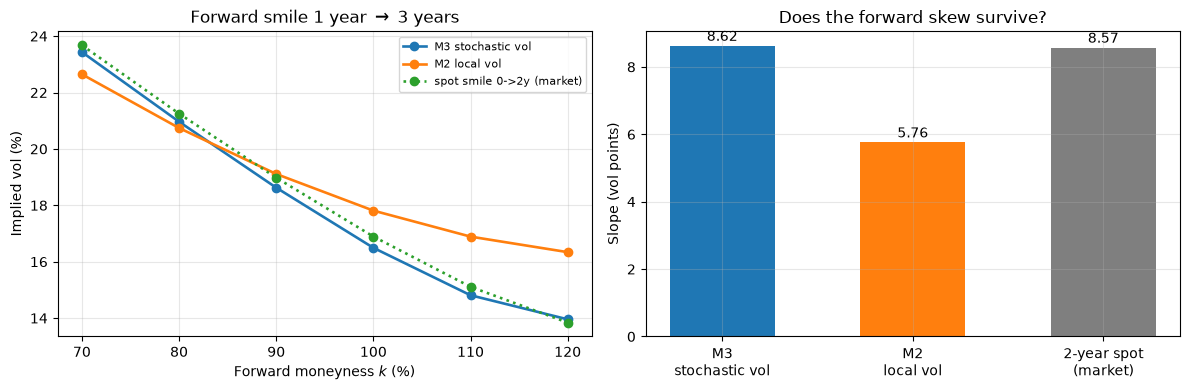

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for n, v in smiles.items():
    st = ':' if 'spot' in n else '-'
    ax[0].plot(ks*100, v*100, st, marker='o', lw=1.9, label=n)
ax[0].set(xlabel='Forward moneyness $k$ (%)', ylabel='Implied vol (%)',
          title='Forward smile 1 year $\\to$ 3 years')
ax[0].legend(fontsize=8)

ax[1].bar(range(3), [slope(v) for v in smiles.values()],
          color=['C0', 'C1', 'C7'], width=.55)
ax[1].set_xticks(range(3)); ax[1].set_xticklabels(['M3\nstochastic vol', 'M2\nlocal vol',
                                                   '2-year spot\n(market)'])
ax[1].set(ylabel='Slope (vol points)', title='Does the forward skew survive?')
for i, v in enumerate(smiles.values()):
    ax[1].text(i, slope(v) + .15, f'{slope(v):.2f}', ha='center')
plt.tight_layout(); plt.show()

**Solution (reference case; forward smile measured on the §4 paths: 200,000 paths, dates 1y and 3y).**

| | Slope = IV(70 %) − IV(110 %) |
|---|---|
| M3 forward smile 1y → 3y | **8.62 vol pts** |
| M2 forward smile 1y → 3y | **5.76 vol pts** |
| 2-year spot smile (market) | 8.57 vol pts |

* **M3 keeps the forward skew.** Heston is time-homogeneous, so the smile seen from 1 year over 2 years looks like today's
  2-year smile (8.62 vs 8.57). The skew is generated by the dynamics ($\rho<0$, vol of vol) and regenerates over time.
* **M2 flattens it by a third** (5.76). The local vol surface itself flattens with maturity: Dupire puts the skew into
  $\sigma_{loc}(S,t)$, and for large $t$ the local skew is much smaller. Seen from 1 year, the future smile is therefore too
  flat. Local vol also gives a **higher forward ATM vol** (17.8 % vs 16.5 %).
* **Same for every term sheet.** The forward smile depends only on the model and the market (the dynamics), not on $B_c$ or $B_p$.
  No barrier enters the calculation, and all teams reuse the same paths and seeds.

**The mechanism behind Q12.** After a non-call date, the remaining product is a **forward-starting Phoenix**: forward digitals
at $B_c$, a forward digital at $B_a$ (the next call) and a forward put at $B_p$, all valued with the **forward smile**. Local vol's
forward smile is **higher at the money and on the upside** (17.8 % vs 16.5 % ATM, 16.9 % vs 14.8 % at 110 %) and **flatter**. The
survivors are spread out more: more later calls, more losses at maturity, fewer coupon-only states (Q13). The forward put
the investor is short is worth more, and the forward digitals at $B_c$ are worth less. Both raise the break-even coupon, by +106 bp.

**Why calibration does not detect it.** Vanillas only pin down the marginals (Gyöngy). The forward smile is a property of the
**transition kernel**, so both models fit all vanillas perfectly and still disagree. Only forward-sensitive instruments
(forward-starts, cliquets, autocall prices) would reveal it, and they are illiquid.

## Q17 ○ (optional) The LSV calibration condition

**Solution.** In M4 the instantaneous variance of $dS/S$ is $L^2(S_t,t)\,v_t$. Gyöngy's mimicking local variance of M4 is
$$\mathbb E\big[L^2(S_t,t)\,v_t \mid S_t=S\big] = L^2(S,t)\,\mathbb E[v_t\mid S_t=S]$$
($L$ is a function of $S_t$, so it comes out of the conditional expectation). M4 reproduces all vanillas if and only if its
marginals equal the market's, i.e. if its mimicking local vol equals Dupire's (the local vol consistent with given marginals
is unique). Hence
$$L^2(S,t)\,\mathbb E[v_t\mid S_t=S] = \sigma^2_{loc}(S,t).$$
* **η = 0**: $dv = \kappa(\theta-v)dt$, deterministic, and with $v_0=\theta$, $v_t\equiv\theta$. Then $L^2\theta = \sigma_{loc}^2$, so
  $L\sqrt{v} = \sigma_{loc}$: this is **M2**.
* **η = 1**: $v$ follows the Heston dynamics of M3. Since the market *is* M3, $\sigma^2_{loc} = \mathbb E^{M3}[v_t\mid S_t]$, so $L\equiv1$
  solves the condition and M4 = **M3**.
* **Particle method.** $\mathbb E[v_t\mid S_t=S]$ is computed under M4's own law, which depends on $L$ at all earlier times.
  The SDE is of **McKean type**: its coefficients depend on its own law. You cannot calibrate $L$ first and simulate after. At
  each time step you estimate $\mathbb E[v_t\mid S_t]$ from the particle cloud (binning or kernel regression), set $L(\cdot,t)$,
  then move the particles one step. Calibration and simulation are done **simultaneously** (Guyon & Henry-Labordère).

## Q18 ● Validating M4 before using it

About 1 minute (5 values of η, 100,000 particles each).

In [25]:
def simulate_lsv(S0, r, q, hp, eta, lv, T, n_steps, n_paths, seed=0,
                 n_bins=80, obs_idx=None):
    # LSV calibrated by the particle method: L^2(S,t) E[v_t|S_t] = sigma_loc^2(S,t).
    rng = np.random.default_rng(seed); dt = T/n_steps; m = n_paths//2
    ka, th, xi, rh = hp['kappa'], hp['theta'], hp['sigma'], hp['rho']
    S = np.full(n_paths, float(S0)); v = np.full(n_paths, float(hp['v0']))
    full = obs_idx is None
    if full:
        out = np.empty((n_steps+1, n_paths)); out[0] = S
    else:
        ov = np.empty((len(obs_idx), n_paths)); rm = np.empty_like(ov)
        k = 0; run = np.full(n_paths, np.inf)
    for i in range(n_steps):
        t = i*dt
        sloc = lv(S, t, S0*np.exp((r - q)*t))
        if i == 0:
            Ev = np.full(n_paths, v[0])            # the whole cloud is at S0
        else:
            x = np.log(S); lo, hi = np.percentile(x, [0.2, 99.8])
            edges = np.linspace(lo, hi, n_bins+1)
            idx = np.clip(np.digitize(x, edges) - 1, 0, n_bins-1)
            cnt = np.bincount(idx, minlength=n_bins)
            sm  = np.bincount(idx, weights=v, minlength=n_bins)
            mean = np.where(cnt > 0, sm/np.maximum(cnt, 1), np.nan)
            ctr = 0.5*(edges[:-1] + edges[1:]); good = np.isfinite(mean)
            mean = np.interp(ctr, ctr[good], mean[good])
            mean = np.convolve(mean, np.ones(5)/5, mode='same')     # smoothing
            mean[:2] = mean[2]; mean[-2:] = mean[-3]
            Ev = np.interp(x, ctr, mean)
        L = np.clip(sloc/np.sqrt(np.maximum(Ev, 1e-6)), 0.1, 5.0)
        vp = np.maximum(v, 0.0); sig = L*np.sqrt(vp)
        z1 = rng.standard_normal(m); z2 = rng.standard_normal(m)
        z1 = np.concatenate([z1, -z1]); z2 = np.concatenate([z2, -z2])
        dW1 = z1*np.sqrt(dt); dW2 = (rh*z1 + np.sqrt(1 - rh**2)*z2)*np.sqrt(dt)
        S = S*np.exp((r - q - 0.5*sig**2)*dt + sig*dW1)
        v = v + ka*(th - vp)*dt + eta*xi*np.sqrt(vp)*dW2
        if full: out[i+1] = S
        else:
            run = np.minimum(run, S)
            if k < len(obs_idx) and (i+1) == obs_idx[k]:
                ov[k] = S; rm[k] = run; run = np.full(n_paths, np.inf); k += 1
    return out if full else (ov, rm)

In [26]:
NL, NPL = 600, 100_000                       # 600 steps: the 6 dates fall on the grid
OIL = np.round(OBS/T*NL).astype(int)
etas = [0.0, 0.25, 0.5, 0.75, 1.0]
ks   = np.array([0.7, 0.8, 0.9, 1.0, 1.1, 1.2])

lsv = {}
for e in etas:
    lsv[e] = simulate_lsv(S0, r, q, HP, e, LV, T, NL, NPL, seed=21, obs_idx=OIL)

# 1) does every value of eta reproduce the vanillas?
print(f"M4: {NPL:,} particles ({NPL//2:,} antithetic pairs), {NL} time steps, seed 21 for every eta.\n")
print("3-year implied vol: does the mixing change the calibration?")
print(f"{'K':>5} {'market':>9}" + "".join(f"{'eta='+str(e):>10}" for e in etas))
for K in [60, 80, 100, 120]:
    ivm = implied_vol(heston_call([K], T, S0, r, q, HP)[0], S0, K, T, r, q)
    row = "".join(
        f"{implied_vol(np.exp(-r*T)*np.maximum(lsv[e][0][-1]-K,0).mean(),S0,K,T,r,q):10.2%}"
        for e in etas)
    print(f"{K:5.0f} {ivm:9.2%}" + row)

M4: 100,000 particles (50,000 antithetic pairs), 600 time steps, seed 21 for every eta.

3-year implied vol: does the mixing change the calibration?
    K    market   eta=0.0  eta=0.25   eta=0.5  eta=0.75   eta=1.0
   60    24.35%    24.14%    24.12%    24.08%    24.05%    24.00%


   80    20.38%    20.33%    20.34%    20.30%    20.26%    20.20%
  100    17.07%    17.12%    17.12%    17.08%    17.03%    16.97%


  120    14.59%    14.67%    14.66%    14.61%    14.56%    14.54%


In [27]:
# 2) the break-even coupon and the forward skew as functions of eta
def phoenix_from_obs(ov):
    n = ov.shape[1]; alive = np.ones(n, bool); pvc = np.zeros(n); pvr = np.zeros(n)
    for k, d in enumerate(OBS):
        perf = ov[k]/S0; df = np.exp(-r*d)
        pvc += np.where(alive & (perf >= Bc), df, 0.0)
        if k < len(OBS) - 1:
            cl = alive & (perf >= Ba); pvr += np.where(cl, df, 0.0); alive &= ~cl
        else:
            pvr += np.where(alive, np.where(perf < Bp, np.minimum(perf, 1.0), 1.0)*df, 0.0)
    return break_even_coupon(pvc.mean(), pvr.mean())

cpn_eta, slope_eta, se_eta = [], [], []
for e in etas:
    ov = lsv[e][0]
    cpn_eta.append(phoenix_from_obs(ov)*200)
    se_eta.append(break_even_coupon_se(*phoenix_paths((ov, None), S0, r, OBS, Ba, Bc, Bp))[1]*2e4)
    R = ov[5]/ov[1]
    sm = np.array([implied_vol(np.exp(-r*2.0)*np.maximum(R - k, 0).mean(), 1.0, k, 2.0, r, q)
                   for k in ks])
    slope_eta.append((sm[0] - sm[4])*100)

print(f"{'eta':>6} {'coupon p.a.':>13} {'SE p.a.':>9} {'fwd smile slope':>17}")
for e, cp, se, pe in zip(etas, cpn_eta, se_eta, slope_eta):
    print(f"{e:6.2f} {cp:12.3f}% {se:6.1f} bp {pe:17.2f}")
print(f"\nRange of the coupon as eta spans [0, 1]: {(max(cpn_eta)-min(cpn_eta))*100:.0f} bp"
      f" of annual coupon (see Q18).")

   eta   coupon p.a.   SE p.a.   fwd smile slope
  0.00        6.971%    5.6 bp              5.52
  0.25        6.662%    5.4 bp              6.29
  0.50        6.311%    5.1 bp              7.10
  0.75        6.011%    4.9 bp              7.90
  1.00        5.738%    4.7 bp              8.54

Range of the coupon as eta spans [0, 1]: 123 bp of annual coupon (see Q18).


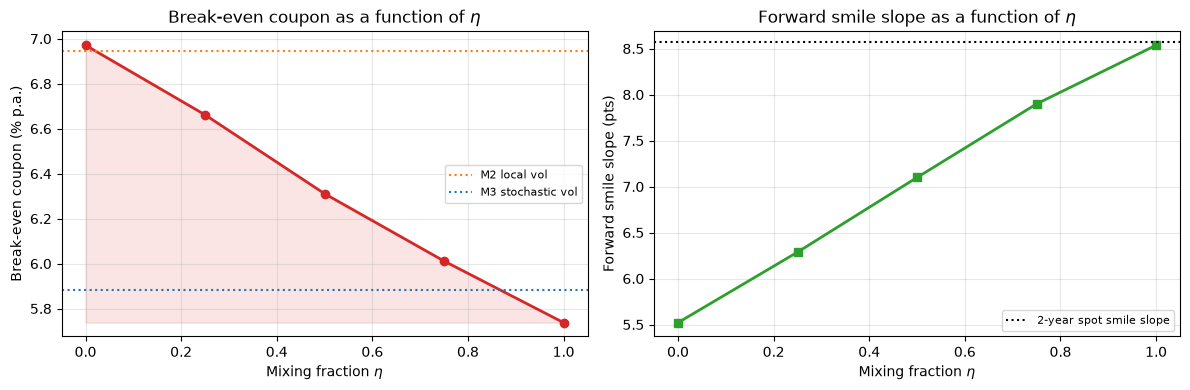

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(etas, cpn_eta, 'o-', lw=2, color='C3')
ax[0].axhline(res_eu['M2 local vol']*200, ls=':', color='C1', label='M2 local vol')
ax[0].axhline(res_eu['M3 stochastic vol']*200, ls=':', color='C0', label='M3 stochastic vol')
ax[0].fill_between(etas, min(cpn_eta), cpn_eta, alpha=.12, color='C3')
ax[0].set(xlabel=r'Mixing fraction $\eta$', ylabel="Break-even coupon (% p.a.)",
          title=r"Break-even coupon as a function of $\eta$")
ax[0].legend(fontsize=8)

ax[1].plot(etas, slope_eta, 's-', lw=2, color='C2')
ax[1].axhline(slope(smiles['spot smile 0->2y (market)']), ls=':', color='k',
              label='2-year spot smile slope')
ax[1].set(xlabel=r'Mixing fraction $\eta$', ylabel='Forward smile slope (pts)',
          title=r'Forward smile slope as a function of $\eta$')
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [29]:
# Solutions add-on: (b) the bounds, with their standard errors
b0  = (cpn_eta[0]  - res_eu['M2 local vol']*200)*100           # in bp p.a.
b1  = (cpn_eta[-1] - res_eu['M3 stochastic vol']*200)*100
s0_ = np.hypot(se_eta[0],  se_eu['M2 local vol']*2e4)
s1_ = np.hypot(se_eta[-1], se_eu['M3 stochastic vol']*2e4)
print(f"eta = 0 vs M2: {b0:+6.1f} bp  (SE {s0_:.1f} bp, z = {b0/s0_:+.1f})")
print(f"eta = 1 vs M3: {b1:+6.1f} bp  (SE {s1_:.1f} bp, z = {b1/s1_:+.1f})")
# 3y vanilla error of M4 at eta = 1, and what it is worth through the coupon's vega (Q20: ~ +57 bp per vol pt)
ivm = {K: implied_vol(heston_call([K], T, S0, r, q, HP)[0], S0, K, T, r, q) for K in [60, 80, 100, 120]}
iv1 = {K: implied_vol(np.exp(-r*T)*np.maximum(lsv[1.0][0][-1]-K, 0).mean(), S0, K, T, r, q) for K in ivm}
print("eta = 1, 3y IV error vs market (vol pts):", {K: round(100*(iv1[K]-ivm[K]), 2) for K in ivm})
print(f"\nCoupon range over eta in [0,1]: {max(cpn_eta):.3f}% -> {min(cpn_eta):.3f}%  = "
      f"{(max(cpn_eta)-min(cpn_eta))*100:.0f} bp  (each point SE ~{np.mean(se_eta):.0f} bp; same seed for all eta)")

eta = 0 vs M2:   +2.5 bp  (SE 6.8 bp, z = +0.4)
eta = 1 vs M3:  -14.5 bp  (SE 5.8 bp, z = -2.5)


eta = 1, 3y IV error vs market (vol pts): {60: -0.35, 80: -0.19, 100: -0.1, 120: -0.05}

Coupon range over eta in [0,1]: 6.971% -> 5.738%  = 123 bp  (each point SE ~5 bp; same seed for all eta)


**Solution (reference case; 100,000 particles, 600 steps, seed 21 for every η).**

**(a) Vanillas.** For every η the 3-year implied vols are within **0.05–0.35 vol pt** of the market (60 %: 24.35 % market vs
24.14 % (η=0) … 24.00 % (η=1); ATM: 17.07 % vs 17.12 % … 16.97 %). The calibration holds for every η, as the theory says.
There is a small drift downwards in the wing as η grows. It is a particle-method error (binning, smoothing, clipping of $L$),
not a model property.

**(b) Bounds.**
* η = 0: 6.971 % vs M2 6.946 %, a gap of **+2.5 bp**, SE ≈ 6.8 bp. This is indistinguishable from zero, so the bound is reproduced.
* η = 1: 5.738 % vs M3 5.882 %, a gap of **−14 bp**, SE ≈ 5.8 bp (about 2.5 SE). This is **real, and it comes from the code, not the model**.
  At η = 1 the exact answer is $L\equiv1$, but the particle method computes $L=\sigma_{loc}/\sqrt{\mathbb E[v|S]}$ with the *numerical*
  Dupire surface (already 0.1–0.2 vol pt low, Q10) and a binned conditional expectation. The resulting vanillas are 0.1–0.35 vol pt
  below market. With a coupon vega of about +57 bp per vol pt (Q20), that accounts for about 6–20 bp. The fix is numerical: a finer
  Dupire grid, more particles and bins, and the same time step as M3.

**(c) Coupon range and forward skew.**

| η | 0 | 0.25 | 0.5 | 0.75 | 1 |
|---|---|---|---|---|---|
| coupon p.a. | 6.97 % | 6.66 % | 6.31 % | 6.01 % | 5.74 % |
| SE | 5.6 bp | 5.4 | 5.1 | 4.9 | 4.7 |
| forward slope (pts) | 5.52 | 6.29 | 7.10 | 7.90 | 8.54 |

The **coupon range is about 123 bp** as η spans [0, 1] (about 105–125 bp once the bound bias of (b) is accounted for; each point
±5 bp, and the SE of the *range* is smaller because all η share the same draws). The coupon falls and the forward skew steepens,
both almost linearly in η. The forward skew is the transmission channel.

**Can η be identified from market data?** **Not from vanillas.** Every η reproduces them by construction, so the vanilla surface
contains **zero information** about η. η could only be pinned down by prices that depend on the forward skew (forward-start
options, cliquets, autocalls: consensus services, broker quotes), which are illiquid and noisy. η is a **model parameter**
in the sense of (R7)(ii). Its range is a direct measure of **model uncertainty**, and it is a better measure than the M2/M3 gap
of Q12 because M4 is the model actually used and every η is fully calibrated (see Q36).

---
# Part 4: The sign of vega and skew, the trap (Q19–Q21, ◆ individual)

## Q19 ◆ Sign of the volatility sensitivity of each component (seller's view)

**Solution.** The seller (issuer) is **short the digital strip** and **long the barrier put**.

* **Digitals at $B_c = 70\,\%$.** The forward is about 100 %, so the barrier is far **below** the forward and the digital
  (pays if $R\ge B_c$) is deep in the money. More vol puts more probability mass below 70 %, so the digital is **worth
  less**: its vega is **negative**. The seller is short, so the seller's vega on the strip is **positive**.
  (For a BS digital call, vega $= -e^{-rT}n(d_2)\,d_1/\sigma$, which is negative as long as $d_1>0$, i.e.
  $K < F e^{\sigma^2T/2}$.)
* **Put (strike 100 %, knock-in 60 %).** A long put gains with vol, so the seller's vega on the put is **positive**.

**The trap.** The naive reasoning "short options = short vega, long put = long vega, so they offset" is wrong. Because the
coupon barrier is below the forward, **both components make the seller long vega**. They add up instead of offsetting.

In [30]:
# Q20: vega by PDE (local vol), +/-1 vol point parallel shift of the implied surface. No Monte Carlo error.
# (Same computation as the course notebook §5, but the bumped local vol surfaces are built once and reused.)
LVB = {b: lv_from_w(np.maximum(IV0 + b, 0.01)**2*Ts_grid[:, None]) for b in (-0.01, 0.0, 0.01)}
def blocks_pde(lv, Bc_, Bp_=None):
    Bp_ = Bp if Bp_ is None else Bp_
    vf = lambda s, t: lv(s, t, S0*np.exp((r - q)*t))
    S, _, P1, _ = phoenix_pde(T, r, q, vf, S0, OBS, Ba, Bc_, 1.0, Bp_)
    S, _, P0_, _ = phoenix_pde(T, r, q, vf, S0, OBS, Ba, Bc_, 0.0, Bp_)
    red_ = np.interp(S0, S, P0_[0])
    return np.interp(S0, S, P1[0]) - red_, red_          # (annuity, redemption leg)

print(f"{'Bc':>5} {'annuity':>8} {'vega ann.':>10} {'vega red.':>10} {'c (p.a.)':>9} "
      f"{'note vega c.dA+dR':>18} {'coupon vega':>13}")
for Bc_ in sorted({Bc, 0.80, 0.90, 0.95, 1.00}):
    out = {b: blocks_pde(LVB[b], Bc_) for b in LVB}
    dA = (out[0.01][0] - out[-0.01][0])/2; dR = (out[0.01][1] - out[-0.01][1])/2
    A0, R0 = out[0.0]; c0 = (1 - R0)/A0
    cu = (1 - out[0.01][1])/out[0.01][0]; cd = (1 - out[-0.01][1])/out[-0.01][0]
    print(f"{Bc_:5.0%} {A0:8.4f} {dA:+10.5f} {dR:+10.5f} {2*c0:9.3%} {c0*dA + dR:+18.5f}"
          f" {(cu-cd)/2*2e4:+10.0f} bp/pt")

   Bc  annuity  vega ann.  vega red.  c (p.a.)  note vega c.dA+dR   coupon vega


  70%   1.8394   -0.03071   -0.00423    6.938%           -0.00529        +58 bp/pt


  80%   1.6003   -0.03276   -0.00423    7.975%           -0.00553        +69 bp/pt


  90%   1.2666   -0.02494   -0.00423   10.077%           -0.00548        +87 bp/pt


  95%   1.0564   -0.01555   -0.00423   12.081%           -0.00517        +98 bp/pt


 100%   0.8109   -0.00194   -0.00423   15.738%           -0.00438       +108 bp/pt


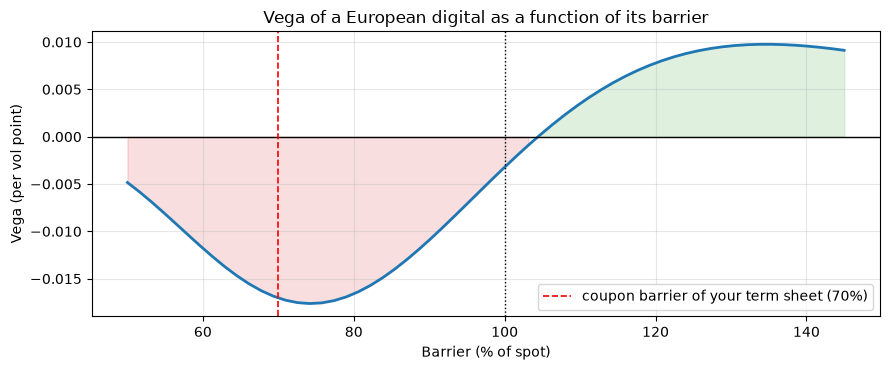

In [31]:
# Vega of a European digital (flat Black-Scholes vol 17%) as a function of its barrier
levels = np.linspace(0.50, 1.45, 60); v0_ = 0.17
def digit(B, v):
    K = B*S0
    return np.exp(-r*T)*(1 - norm.cdf((np.log(K/S0) - (r - q - 0.5*v**2)*T)/(v*np.sqrt(T))))
vega = [(digit(B, v0_ + 0.005) - digit(B, v0_ - 0.005)) for B in levels]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(levels*100, vega, lw=2); ax.axhline(0, color='k', lw=1)
ax.axvline(100, color='k', ls=':', lw=1)
ax.axvline(Bc*100, color='r', ls='--', lw=1.2, label=f'coupon barrier of your term sheet ({Bc:.0%})')
ax.fill_between(levels*100, vega, 0, where=np.array(vega) < 0, alpha=.15, color='C3')
ax.fill_between(levels*100, vega, 0, where=np.array(vega) > 0, alpha=.15, color='C2')
ax.set(xlabel='Barrier (% of spot)', ylabel='Vega (per vol point)',
       title="Vega of a European digital as a function of its barrier")
ax.legend(); plt.tight_layout(); plt.show()

## Q20 ◆ Numerical vegas and the effect of raising $B_c$ to 95 %

**Solution (reference case, PDE under local vol, ±1 vol pt parallel shift).**

| | $B_c$ = 70 % | $B_c$ = 95 % |
|---|---|---|
| annuity (per unit of semi-annual coupon) | 1.839 | 1.056 |
| vega of the digital strip (per unit coupon) | **−0.0307** / vol pt | **−0.0156** / vol pt |
| vega of the redemption leg (= −vega of the put) | **−0.0042** / vol pt | −0.0042 / vol pt |
| note vega to the investor $c\,dA + dR$ | −0.0053 | −0.0052 |
| break-even coupon at −1 / 0 / +1 pt | 6.37 / 6.94 / 7.52 % | 11.11 / 12.08 / 13.07 % |
| coupon vega | **+58 bp per vol pt** | **+98 bp per vol pt** |

* **The intuition is confirmed.** The digital strip loses value when vol rises (negative vega) and the put gains (the redemption
  leg falls). The note loses about 0.5 % of notional per vol point for the investor, so the **seller is long vega** on both legs
  and the break-even coupon rises with vol.
* **Raising $B_c$ to 95 %.** The strip's vega is **halved** (−0.031 → −0.016) but **keeps its sign**: 95 % is still below the
  zero-vega point, which for a digital is $K\approx F e^{\sigma^2 t/2}$, i.e. 100–105 % depending on the date (see the BS plot).
  The scan in the cell above shows the strip's vega is not even monotone (−0.031 at 70 %, −0.033 at 80 %), then shrinks
  towards zero (−0.016 at 95 %, −0.002 at 100 %). It would flip sign just above the forward, which the autocall at 100 % rules out. The redemption leg does not depend on $B_c$, so its vega is unchanged. The **coupon** vega grows (+98 bp/pt) because
  the annuity is much smaller, so the same value change needs a bigger coupon move.
* **Lesson.** The sign of a building block's vega depends on **where the barrier sits relative to the forward**. Never infer it
  from "long/short option".

In [32]:
# Q21: skew sensitivity. Tilt the implied surface around the forward: IV(y) -> IV(y) + beta*y, y = ln(K/F).
# beta = -0.02 steepens the skew (about +1 vol pt at the 60% strike, -0.2 pt at 110%).
def tilt(beta): return lv_from_w(np.maximum(IV0 + beta*ys_grid[None, :], 0.01)**2*Ts_grid[:, None])
LVS = {beta: tilt(beta) for beta in (-0.02, 0.0, 0.02)}

print("Skew sensitivity = value(steeper skew) - value(flatter skew), /2   (PDE, local vol)")
print(f"{'Bc':>5} {'Bp':>5} {'d(c x annuity)':>15} {'d(redemption)':>14} {'note (investor)':>16} {'coupon':>11}")
for Bc_, Bp_ in [(Bc, Bp), (0.65, 0.50), (0.75, 0.65), (0.95, 0.50), (0.95, 0.65)]:
    out = {b: blocks_pde(LVS[b], Bc_, Bp_) for b in LVS}
    A0, R0 = out[0.0]; c0 = (1 - R0)/A0
    dA = (out[-0.02][0] - out[0.02][0])/2; dR = (out[-0.02][1] - out[0.02][1])/2
    cst = (1 - out[-0.02][1])/out[-0.02][0]; cfl = (1 - out[0.02][1])/out[0.02][0]
    print(f"{Bc_:5.0%} {Bp_:5.0%} {c0*dA:+15.5f} {dR:+14.5f} {c0*dA + dR:+16.5f} {(cst-cfl)/2*2e4:+8.1f} bp")

Skew sensitivity = value(steeper skew) - value(flatter skew), /2   (PDE, local vol)
   Bc    Bp  d(c x annuity)  d(redemption)  note (investor)      coupon


  70%   60%        -0.00109       -0.00167         -0.00276    +30.0 bp


  65%   50%        -0.00105       -0.00279         -0.00384    +39.8 bp


  75%   65%        -0.00095       -0.00112         -0.00207    +23.9 bp


  95%   50%        +0.00026       -0.00279         -0.00253    +47.9 bp


  95%   65%        +0.00034       -0.00112         -0.00078    +14.8 bp


## Q21 ◆ Same question for the skew, and the prudent pricing practice

**Solution.** Steepen the skew by rotating the smile around the forward (more vol at low strikes, less at high strikes). Each
digital feels **two opposite effects**: a digital call is $\approx$ BS digital$(\sigma(K))$ $-\ \text{vega}\times\partial\sigma/\partial K$.
* **Level effect.** The vol *at* the barrier goes up, and since the digital's vega is negative (Q19) its value goes **down**.
* **Slope effect.** A more negative slope pushes the value **up**.
* **Which wins depends on where the barrier sits relative to the pivot.** Far below the forward ($B_c$ = 70 %) the level effect
  wins and the strip **loses** value (−0.0011). Near the forward ($B_c$ = 95 %) the slope effect wins and the strip **gains** (+0.0003).
  **The sign of the digital strip's skew sensitivity flips with the term sheet.**
* **The put at $B_p$.** More vol at low strikes makes the put **more expensive** in every case. The seller, long the put, gains, and
  the redemption leg falls (−0.0011 to −0.0028).

So for the skew, the components do **not** have a stable sign. At 70 % the two legs push the same way, at 95 % they push in
opposite directions, and the net is then much smaller (−0.0008 at 95 % / 65 %). The answer also depends on the bump convention
(the pivot of the rotation) and on the spot during the life: as the spot drifts down towards $B_c$, a "far" barrier becomes
a "near" one. That is the trap: unlike vega, the skew exposure is **not stable in sign**.

**Prudent pricing practice.** When the net sign of a parameter is not stable, you **do not price at the mid and net the
offsetting sensitivities**. A prudent trader:
* prices with the parameter **on the adverse side for the position**, and re-checks it as the position evolves, since the sign
  can flip with spot and time. Equivalently, prices under both bumps (and the model range) and **keeps the worse value**;
* charges each component its **own bid/offer** on the parameter instead of netting them;
* books a **parameter uncertainty reserve** (accounting) for the range, and keeps limits on the exposure.

---
# Part 5: Choosing a model by the faithfulness of its sensitivities (Q22–Q27)

## Q22 ● Delta-hedging backtest of the European-barrier put ("reality" = M3)

In [33]:
# Deltas of M1 and M2 by PDE; deltas of M3 on an (S, v, tau) grid by the COS method
vf_lv = lambda s, t: LV(s, t, S0*np.exp((r - q)*t))
Sg, tg, P_lv, D_lv = pde_european(dip, T, r, q, vf_lv)
_,  _,  P_bs, D_bs = pde_european(dip, T, r, q, lambda s, t: ATM)

Sgh  = np.exp(np.linspace(np.log(15.), np.log(320.), 140))
vgh  = np.linspace(0.004, 0.30, 16)
taug = np.linspace(0.0, T, 31)
Vh = np.zeros((len(taug), len(vgh), len(Sgh)))
for i, tau in enumerate(taug):
    if tau <= 1e-8:
        Vh[i] = dip(Sgh)[None, :]; continue
    for j, v in enumerate(vgh):
        p = dict(HP); p['v0'] = v
        a, b = _cos_range(tau, r, q, v, p['theta'])
        xg = np.linspace(a, b, 2000)
        dens = heston_density(xg, tau, r, q, N=1024, **p)
        Vh[i, j] = np.exp(-r*tau)*_trapz(dip(Sgh[:, None]*np.exp(xg)[None, :])
                                         * dens[None, :], xg, axis=1)
Dh = np.gradient(Vh, Sgh, axis=2)

itp = {'M3 stochastic vol': RegularGridInterpolator((taug, vgh, Sgh), Dh,
                                bounds_error=False, fill_value=None),
       'M2 local vol'      : RegularGridInterpolator((tg, Sg), D_lv,
                                bounds_error=False, fill_value=None),
       'M1 flat Black-Scholes': RegularGridInterpolator((tg, Sg), D_bs,
                                bounds_error=False, fill_value=None)}
P0 = {'M3 stochastic vol': float(RegularGridInterpolator((taug, vgh, Sgh), Vh)([[T, HP['v0'], S0]])[0]),
      'M2 local vol'      : float(np.interp(S0, Sg, P_lv[0])),
      'M1 flat Black-Scholes': float(np.interp(S0, Sg, P_bs[0]))}
print("Initial prices:", {k: f"{v:.4%}" for k, v in P0.items()})

Initial prices: {'M3 stochastic vol': '5.5678%', 'M2 local vol': '5.5002%', 'M1 flat Black-Scholes': '2.5175%'}


In [34]:
NH, NPH = 156, 40_000                      # weekly rebalancing
pth, vpt = simulate_heston(S0, r, q, HP, T, NH, NPH, seed=99, return_var=True)  # full paths
th = np.linspace(0, T, NH + 1); dth = T/NH

res_hedge = {}
for name, f in itp.items():
    cash = np.full(NPH, P0[name]); pos = np.zeros(NPH)
    for i in range(NH):
        S, v, t = pth[i], vpt[i], th[i]
        d = f(np.stack([np.full_like(S, T - t), v, S], -1)) if '3' in name \
            else f(np.stack([np.full_like(S, t), S], -1))
        cash -= (d - pos)*S; pos = d
        cash *= np.exp(r*dth); cash += pos*S*(np.exp(q*dth) - 1)
    pl = cash + pos*pth[-1] - dip(pth[-1])
    res_hedge[name] = (P0[name], pl.mean(), pl.std(),
                       np.percentile(pl, 5), np.percentile(pl, 1), pl)

print(f"Backtest: {NPH:,} paths of the reference model M3, {NH} weekly rebalancing dates.\n")
print(f"{'Deltas from':24s} {'price 0':>8s} {'mean P&L':>10s} {'SE mean':>8s} {'std dev':>9s}"
      f" {'q 5%':>9s} {'q 1%':>9s}")
for k, (a, b, c_, d, e, pl) in res_hedge.items():
    print(f"{k:24s} {a:8.2%} {b:+10.2%} {mc_se(pl):8.2%} {c_:9.2%} {d:+9.2%} {e:+9.2%}")

Backtest: 40,000 paths of the reference model M3, 156 weekly rebalancing dates.

Deltas from               price 0   mean P&L  SE mean   std dev      q 5%      q 1%
M3 stochastic vol           5.57%     -0.02%    0.04%     7.72%   -15.59%   -29.56%
M2 local vol                5.50%     -0.09%    0.03%     7.26%   -11.35%   -24.27%
M1 flat Black-Scholes       2.52%     -3.27%    0.04%     8.90%   -19.66%   -40.19%


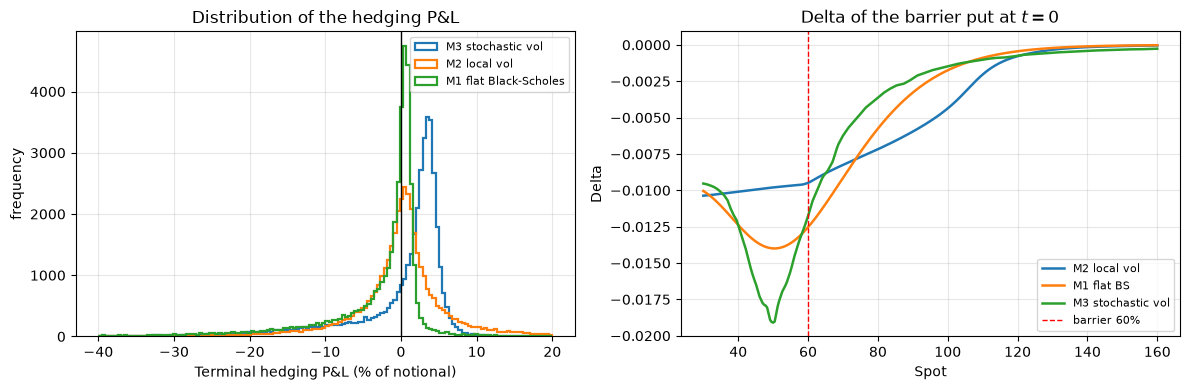

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, (_, _, _, _, _, pl) in res_hedge.items():
    ax[0].hist(pl*100, bins=140, range=(-40, 20), histtype='step', lw=1.6, label=k)
ax[0].axvline(0, color='k', lw=1)
ax[0].set(xlabel='Terminal hedging P&L (% of notional)', ylabel='frequency',
          title='Distribution of the hedging P&L'); ax[0].legend(fontsize=8)

kk = np.linspace(30, 160, 300); i0 = 0
ax[1].plot(kk, np.interp(kk, Sg, D_lv[i0]), label='M2 local vol', lw=1.8)
ax[1].plot(kk, np.interp(kk, Sg, D_bs[i0]), label='M1 flat BS', lw=1.8)
ax[1].plot(kk, itp['M3 stochastic vol'](np.stack([np.full_like(kk, T),
           np.full_like(kk, HP['v0']), kk], -1)), label='M3 stochastic vol', lw=1.8)
ax[1].axvline(Bp*S0, color='r', ls='--', lw=1, label=f'barrier {Bp:.0%}')
ax[1].set(xlabel='Spot', ylabel='Delta', title='Delta of the barrier put at $t=0$')
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

**Solution (reference case; 40,000 M3 paths, 156 weekly rebalancings, each hedger starts with its own price).**

| Deltas from | Initial price | Mean P&L (SE) | Std dev | 5 % quantile | 1 % quantile |
|---|---|---|---|---|---|
| M3 (true model) | 5.57 % | −0.02 % (0.04) | 7.72 % | −15.6 % | −29.6 % |
| M2 local vol | 5.50 % | −0.09 % (0.03) | **7.26 %** | **−11.4 %** | −24.3 % |
| M1 flat BS | 2.52 % | **−3.27 %** (0.04) | 8.90 % | −19.7 % | −40.2 % |

* M1 **loses about 3.3 % on average**: it sold the put for 2.52 % while it is worth 5.57 %.
* M2 and M3 have **zero mean** (within 2–3 SE) and a **large dispersion**: the standard deviation (7–8 %) exceeds the price of the
  put itself.

## Q23 ● Mean vs standard deviation: price error vs greeks error

**Solution.**
* The **mean** of the hedging P&L measures the **price error**. Under the true measure (here the simulation is under $\mathbb Q$),
  a hedger who charges $P^{model}$ and replicates ends with an expected P&L ≈ $P^{model} - P^{true}$, whatever the hedge. M1: 2.52 − 5.57 = −3.05 %,
  observed −3.27 %. M2 and M3: about 0.
* The **standard deviation** (and the tail quantiles) measures the **quality of the hedge**: how well the greeks replicate the
  payoff path by path. It mixes greeks error, discrete rebalancing, the unhedgeable vol risk (incompleteness) and the gap risk
  at the barrier.

A model can be right on average and hedge badly (high std), or hedge well and be biased (Q22 caveat (c)).

In [36]:
# Q24 add-on 1: the minimum-variance delta in M3:  Delta_MV = dV/dS + (rho*xi/S) dV/dv
#             (from d<V,S>/d<S,S> with dS = S sqrt(v) dW1, dv = xi sqrt(v) dW2, d<W1,W2> = rho dt)
# Q24 add-on 2: complete the market with a vanilla (4-year ATM call): hedge dV/dv with the call, then delta.
Dv = np.gradient(Vh, vgh, axis=1)
itp_mv = RegularGridInterpolator((taug, vgh, Sgh), Dh + HP['rho']*HP['sigma']*Dv/Sgh[None, None, :],
                                 bounds_error=False, fill_value=None)
KH, TH = 100.0, 4.0
Ch = np.zeros_like(Vh)
for i, tau in enumerate(taug):
    tc = tau + (TH - T)
    for j, v in enumerate(vgh):
        p = dict(HP); p['v0'] = v
        a, b = _cos_range(tc, r, q, v, p['theta']); xg = np.linspace(a, b, 2000)
        dens = heston_density(xg, tc, r, q, N=1024, **p)
        Ch[i, j] = np.exp(-r*tc)*_trapz(np.maximum(Sgh[:, None]*np.exp(xg)[None, :] - KH, 0)*dens[None, :], xg, axis=1)
CS, Cv = np.gradient(Ch, Sgh, axis=2), np.gradient(Ch, vgh, axis=1)
wC = Dv/Cv                                   # units of call per unit of put: vega-neutral (w.r.t. v)
mk = lambda A: RegularGridInterpolator((taug, vgh, Sgh), A, bounds_error=False, fill_value=None)
itp_C, itp_w, itp_dS = mk(Ch), mk(wC), mk(Dh - wC*CS)

def backtest(delta_fn, price0, use_call=False):
    cash = np.full(NPH, price0); pos = np.zeros(NPH); posC = np.zeros(NPH)
    for i in range(NH):
        S, v, t = pth[i], vpt[i], th[i]
        pts = np.stack([np.full_like(S, T - t), v, S], -1)
        if use_call:
            w, C = itp_w(pts), itp_C(pts); cash -= (w - posC)*C; posC = w; d = itp_dS(pts)
        else:
            d = delta_fn(pts)
        cash -= (d - pos)*S; pos = d
        cash *= np.exp(r*dth); cash += pos*S*(np.exp(q*dth) - 1)
    CT = itp_C(np.stack([np.zeros(NPH), vpt[-1], pth[-1]], -1))
    return cash + pos*pth[-1] + posC*CT - dip(pth[-1])

runs = {'M3 delta at fixed v (course)': res_hedge['M3 stochastic vol'][-1],
        'M3 minimum-variance delta'   : backtest(itp_mv, P0['M3 stochastic vol']),
        'M3 delta + vega (4y call)'   : backtest(None, P0['M3 stochastic vol'], use_call=True),
        'M2 local vol delta (course)' : res_hedge['M2 local vol'][-1]}
print(f"Backtest: {NPH:,} M3 paths, {NH} weekly rebalancings\n")
print(f"{'Hedge':30s} {'mean':>8s} {'SE':>6s} {'std':>7s} {'IQR':>7s} {'q5%':>8s} {'q1%':>8s}")
for k, pl in runs.items():
    print(f"{k:30s} {pl.mean():+8.2%} {mc_se(pl):6.2%} {pl.std():7.2%} "
          f"{np.percentile(pl,75)-np.percentile(pl,25):7.2%} {np.percentile(pl,5):+8.2%} {np.percentile(pl,1):+8.2%}")

Backtest: 40,000 M3 paths, 156 weekly rebalancings

Hedge                              mean     SE     std     IQR      q5%      q1%
M3 delta at fixed v (course)     -0.02%  0.04%   7.72%   4.58%  -15.59%  -29.56%
M3 minimum-variance delta        -0.01%  0.03%   6.39%   4.68%   -9.80%  -21.04%
M3 delta + vega (4y call)        +0.16%  0.04%   7.66%   0.69%   -3.34%  -14.81%
M2 local vol delta (course)      -0.09%  0.03%   7.26%   4.83%  -11.35%  -24.27%


## Q24 ● M2 vs M3: does hedging tell them apart? What dominates the residual risk?

**Solution.**
* **Same price, similar hedges.** M2 and M3 both have zero mean, and their standard deviations are close (7.3 % vs 7.7 %). In this
  backtest the local vol delta even does **slightly better** than the "true" model's delta. Hedging performance does
  **not** clearly separate them, and it certainly does not crown the true model.
* **(a) The M3 delta at fixed $v$ is not the minimum-variance delta.** With $\rho\neq0$, spot moves come with predictable vol moves.
  The variance-minimising hedge is $\Delta_{MV} = \partial_S V + \frac{\rho\xi}{S}\partial_v V$. With $\rho=-0.7$ and the put's
  positive vega, this lowers the delta. The local vol delta implicitly contains a similar correction (the smile moves with the
  spot in local vol, a "sticky local vol" regime, with a skew-stickiness ratio, SSR, of about 2). That is why it competes so well. The add-on
  shows the minimum-variance delta cutting the M3 standard deviation from **7.72 % to 6.39 %** and the 5 % quantile from −15.6 % to
  −9.8 %: the course's M3 delta was simply not the best delta.
* **(b) What dominates.** Most of the residual is the **volatility risk that the underlying cannot hedge** (Q9: 2 Brownian
  motions, 1 hedging asset), plus the **gap risk** at the barrier close to maturity (Q25), plus weekly discretisation.
  - A **better model** does not remove it: we already hedge with the *true* model.
  - **Other instruments** do: adding a vanilla to hedge the exposure to $v$ completes the market. The add-on hedges with a 4-year
    ATM call. The **bulk** of the distribution collapses (interquartile range and 5 % quantile from −15.6 % to about −3.3 %), but
    the standard deviation barely moves (7.7 %). It is now driven by a few paths that end **next to the barrier**, where the
    put's vega and delta explode in the last weeks and weekly rebalancing cannot follow. That is the **gap risk** of Q25, which no
    instrument and no model removes.

**Conclusion.** This residual is **not model risk**. It is **market incompleteness** when hedging with the underlying alone.
It must be managed with vanillas (a vega hedge), limits and reserves, not by changing the model.

## Q25 ● Delta of the Phoenix around the protection barrier near maturity

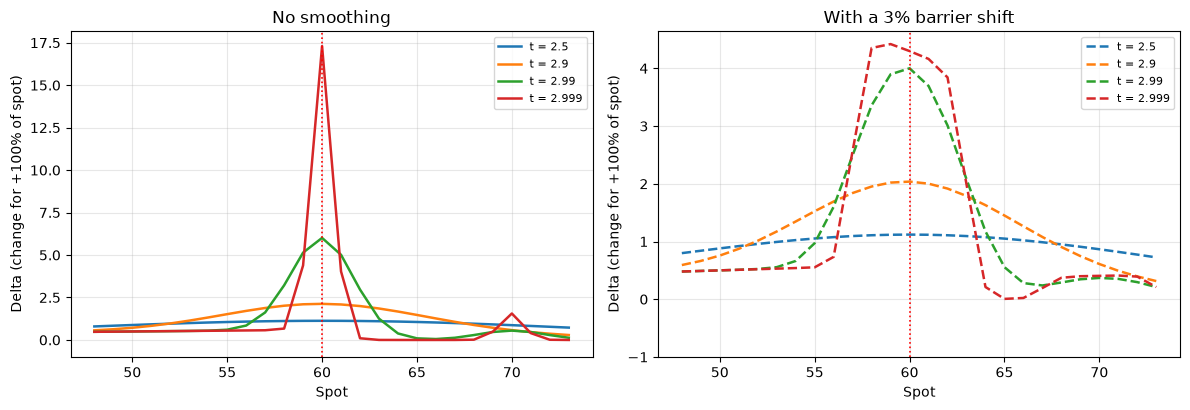

  shift  |delta| max   break-even coupon p.a.


   0.0%         24.1                   6.938%


   0.5%         18.0                   6.939%


   1.0%         12.0                   6.936%


   2.0%          6.4                   6.930%


   3.0%          4.5                   6.920%


   5.0%          2.9                   6.889%


In [37]:
CPN = res_eu['M2 local vol']      # local vol break-even coupon (§4, European barrier)
grid = np.arange(Bp*S0 - 12., Bp*S0 + 14., 1.)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for sh, style in [(0.0, '-'), (0.03, '--')]:
    S, tt2, P, D = phoenix_pde(T, r, q, vf_lv, S0, OBS, Ba, Bc, CPN, Bp,
                               shift=sh, n_per=800)
    for t_, col in zip([2.5, 2.9, 2.99, 2.999], ['C0', 'C1', 'C2', 'C3']):
        i = np.argmin(abs(tt2 - t_))
        ax[0 if sh == 0 else 1].plot(grid, np.interp(grid, S, D[i]*S), style,
                                     color=col, lw=1.8, label=f't = {t_}')
for a, ttl in zip(ax, ['No smoothing', 'With a 3% barrier shift']):
    a.axvline(Bp*S0, color='r', ls=':', lw=1.2)
    a.set(xlabel='Spot', ylabel='Delta (change for +100% of spot)', title=ttl)
    a.legend(fontsize=8)
ax[0].set_ylim(-1, None); ax[1].set_ylim(-1, None)
plt.tight_layout(); plt.show()

print(f"{'shift':>7s} {'|delta| max':>12s} {'break-even coupon p.a.':>24s}")
for sh in [0.0, 0.005, 0.01, 0.02, 0.03, 0.05]:
    S, tt2, P, D = phoenix_pde(T, r, q, vf_lv, S0, OBS, Ba, Bc, CPN, Bp,
                               shift=sh, n_per=800)
    m = (S > Bp*S0 - 12) & (S < Bp*S0 + 15)
    f = lambda cc: np.interp(S0, S, phoenix_pde(T, r, q, vf_lv, S0, OBS, Ba, Bc,
                                                cc, Bp, shift=sh)[2][0]) - 1.0
    print(f"{sh:7.1%} {np.abs(D[-2][m]*S[m]).max():12.1f} {brentq(f,0,.15,xtol=1e-7)*200:23.3f}%")

In [38]:
# Solutions add-on: max |delta| next to the barrier at each date, its grid dependence, and the theoretical scale
print("max |S dV/dS| within [Bp-12, Bp+14] (PDE, local vol, n_per = 800)")
print(f"{'n_space':>8s}" + "".join(f"{f't={t_}':>10s}" for t_ in [2.5, 2.9, 2.99, 2.999]))
for ns in [601, 1201, 2401]:
    S, tt2, P, D = phoenix_pde(T, r, q, vf_lv, S0, OBS, Ba, Bc, CPN, Bp, n_space=ns, n_per=800)
    m = (S > Bp*S0 - 12) & (S < Bp*S0 + 14)
    row = []
    for t_ in [2.5, 2.9, 2.99, 2.999]:
        i = np.argmin(abs(tt2 - t_)); row.append(np.abs(D[i][m]*S[m]).max())
    print(f"{ns:8d}" + "".join(f"{x:10.1f}" for x in row))
sig_B = float(vf_lv(np.array([Bp*S0]), 2.9)[0]); J = 1 - Bp
print(f"\nTheory: a payoff jump J = 1 - Bp = {J:.2f} at the barrier gives max delta ~ J/(sigma*sqrt(2*pi*tau)), "
      f"sigma_loc(Bp) ~ {sig_B:.1%}:")
print("  " + "  ".join(f"tau={tau:<6}: {J/(sig_B*np.sqrt(2*np.pi*tau)):6.1f}" for tau in [0.5, 0.1, 0.01, 0.001]))

max |S dV/dS| within [Bp-12, Bp+14] (PDE, local vol, n_per = 800)
 n_space     t=2.5     t=2.9    t=2.99   t=2.999


     601       1.1       2.1       6.0      14.9


    1201       1.1       2.1       6.0      17.3


    2401       1.1       2.1       6.8      40.3

Theory: a payoff jump J = 1 - Bp = 0.40 at the barrier gives max delta ~ J/(sigma*sqrt(2*pi*tau)), sigma_loc(Bp) ~ 28.1%:
  tau=0.5   :    0.8  tau=0.1   :    1.8  tau=0.01  :    5.7  tau=0.001 :   18.0


**Solution.**
* **What we see (reference case).** The max delta next to $B_p$ is **1.1 at t = 2.5, 2.1 at t = 2.9, 6 at t = 2.99, and 15 to 40
  at t = 2.999** depending on the grid. It is a spike centred on the barrier that grows like $1/\sqrt{T-t}$. The theory for a payoff
  jump $J = 1-B_p = 40\,\%$ gives $J/(\sigma\sqrt{2\pi\tau})$ ≈ 0.8, 1.8, 5.7, 18 with $\sigma_{loc}(B_p)\approx 28\,\%$, which matches the
  PDE until the grid can no longer resolve the spike. The delta is the payoff jump spread over a vanishing range of spot.
* **Can a desk execute it?** No. A delta of 20 in the (R8) unit means a **1 % move of the spot changes the value by 20 % of
  notional**. The hedge would be to buy or sell **20 times the notional** in stock as the spot crosses the barrier, back and
  forth on every tick. That is impossible for liquidity reasons, and it would move the market against you (and invite
  manipulation near the barrier). The loss is of the order of the payoff jump **whatever the model**. This is the **gap risk** of (R8).
* **Validator's remark.** Very close to maturity the delta is **a numerical artifact**. Theoretically it is unbounded as
  $\tau\to0$, so the computed maximum is bounded by the grid: about $J/\Delta x$ in space, and by the time step. Refining the grid
  changes the number (the table above: 15 / 17 / 40 at t = 2.999 with 601 / 1201 / 2401 nodes, but stable at t ≤ 2.99). A validator
  should not use a grid-dependent value. Retain a value at a horizon
  consistent with how often the desk can actually rebalance (e.g. 1–2 days before maturity, $\tau\approx 0.005$), or the delta of
  the **smoothed** payoff (barrier shift, Q26), and treat the remainder as gap risk to be reserved.

In [39]:
# Q26 add-on: ADVERSE (one-sided) barrier shift. Each indicator replaced by a ramp on the side that hurts the desk:
#   protection 1{R >= Bp}: ramp on [Bp - 2eps, Bp]  (assume protection more often: the desk's long put is worth less)
#   coupon     1{R >= Bc}: ramp on [Bc - 2eps, Bc]  (assume coupons more often: the desk pays more)
#   autocall stays sharp.
def phoenix_pde_adverse(vol_fn, coupon, eps, n_space=1201, n_per=300, S_min=5., S_max=500.):
    x = np.linspace(np.log(S_min), np.log(S_max), n_space); S = np.exp(x); perf = S/S0
    down  = (lambda p, lv: (p >= lv).astype(float)) if eps <= 0 else \
            (lambda p, lv: np.clip((p - (lv - 2*eps))/(2*eps), 0., 1.))
    sharp = lambda p, lv: (p >= lv).astype(float)
    dates = [0.0] + list(OBS); ip = down(perf, Bp)
    V = coupon*down(perf, Bc) + ip + (1 - ip)*np.minimum(perf, 1.0)
    for k in range(len(OBS)-1, -1, -1):
        dt = (dates[k+1] - dates[k])/n_per
        for n in range(n_per-1, -1, -1):
            sig = np.asarray(vol_fn(S, dates[k] + n*dt), float)*np.ones(n_space)
            V = _cn_step(V, S, x, dt, r, q, sig)
            if k == len(OBS)-1 and n == n_per-2: Vlast = V.copy()
        if k > 0:
            ia = sharp(perf, Ba); V = ia*(1 + coupon) + (1 - ia)*(V + coupon*down(perf, Bc))
    return S, V, Vlast

def be_coupon_adverse(eps):          # the value is affine in the coupon: two PDE runs suffice
    v0 = np.interp(S0, *phoenix_pde_adverse(vf_lv, 0.0, eps)[:2])
    v1 = np.interp(S0, *phoenix_pde_adverse(vf_lv, 1.0, eps)[:2])
    return (1 - v0)/(v1 - v0)
c_sharp = be_coupon_adverse(0.0)
print(f"{'eps':>6s} {'coupon p.a. (adverse)':>22s} {'margin vs sharp':>16s} {'|delta| max near T':>19s}")
for eps in [0.0, 0.005, 0.01, 0.02, 0.03, 0.05]:
    ce = be_coupon_adverse(eps)
    S, _, Vl = phoenix_pde_adverse(vf_lv, CPN, eps, n_per=800)
    m = (S > Bp*S0 - 12) & (S < Bp*S0 + 15)
    dl = np.abs(np.gradient(Vl, np.log(S))[m]).max()
    print(f"{eps:6.1%} {2*ce:21.3%} {2e4*(c_sharp-ce):13.1f} bp {dl:19.1f}")

   eps  coupon p.a. (adverse)  margin vs sharp  |delta| max near T


  0.0%                6.938%           0.0 bp                17.3


  0.5%                6.853%           8.6 bp                14.1


  1.0%                6.763%          17.6 bp                11.3


  2.0%                6.589%          35.0 bp                 6.4


  3.0%                6.420%          51.8 bp                 4.5


  5.0%                6.098%          84.0 bp                 2.9


## Q26 ● Barrier shift: smoothing the indicators

**Solution (reference case, course table + add-on).**

| half-width ε | 0 | 0.5 % | 1 % | 2 % | 3 % | 5 % |
|---|---|---|---|---|---|---|
| max \|delta\| (symmetric) | 24.1 | 18.0 | 12.0 | 6.4 | 4.5 | 2.9 |
| coupon p.a. (symmetric) | 6.938 % | 6.939 % | 6.936 % | 6.930 % | 6.920 % | 6.889 % |

* **Observation.** Smoothing **caps the delta**: about ×5 smaller at ε = 3 % and roughly $\propto 1/\varepsilon$. The hedge becomes executable. With
  *symmetric* smoothing, though, the coupon **barely moves** (−2 bp at 3 %, −5 bp at 5 %).
* **Why symmetric smoothing generates almost no margin.** A call spread centred on the barrier over-pays on one side and
  under-pays on the other by the same area. The two errors cancel to first order and only a second-order term
  ($\propto\varepsilon^2\times$ the slope of the density) remains. Symmetric smoothing makes the hedge executable but **does not pay
  for** the gap risk.
* **What a desk actually does.** It shifts each barrier **to the side that is adverse to its own position** (one-sided call
  spread, "overhedge"), so that the smoothed payoff always *dominates* what the desk owes. The desk is long the put, so it
  assumes protection holds slightly *more* often (ramp below $B_p$). The desk pays the coupons, so it assumes coupons are paid
  slightly *more* often (ramp below $B_c$). The add-on table shows that this one-sided shift produces a **real margin**,
  tens of bp of coupon at ε = 2–3 %, while capping the delta in the same way. That margin is the **barrier-shift reserve**: it
  pays for the gap risk, and it is released when the barrier risk disappears (Q32).
* The size of ε is set by **liquidity** (how much stock the desk can trade near the barrier) and the **position size**, and it is a
  model-risk parameter that the control functions must validate.

## Q27 ○ (optional) Delta near the autocall barrier before an observation date

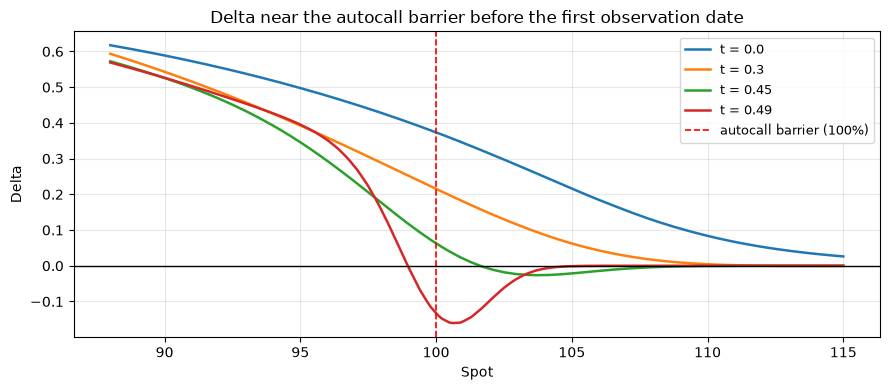

In [40]:
# Delta near the autocall barrier, just before an observation date
S, tt2, P, D = phoenix_pde(T, r, q, vf_lv, S0, OBS, Ba, Bc, CPN, Bp, n_per=800)
gg = np.linspace(88, 115, 200)
fig, ax = plt.subplots(figsize=(9, 4))
for t_ in [0.0, 0.30, 0.45, 0.49]:
    i = np.argmin(abs(tt2 - t_))
    ax.plot(gg, np.interp(gg, S, D[i]*S), lw=1.8, label=f't = {t_}')
ax.axvline(Ba*S0, color='r', ls='--', lw=1.2, label="autocall barrier (100%)")
ax.axhline(0, color='k', lw=1)
ax.set(xlabel='Spot', ylabel='Delta', title="Delta near the autocall barrier before the first observation date")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

In [41]:
# Size of the jump across Ba on the first observation date. Just before t = 0.5:
#   above Ba: 1 + c (called);  below Ba: c (coupon, since Bc < Ba) + continuation value V(0.5+, S)
S, tt2, P, D = phoenix_pde(T, r, q, vf_lv, S0, OBS, Ba, Bc, CPN, Bp, n_per=800)
i = np.argmin(abs(tt2 - 0.5))                        # this row of P is the continuation value V(0.5+)
for s_ in [95., 98., 99.9]:
    print(f"continuation value at S = {s_:5.1f}: {np.interp(s_, S, P[i]):.4f}")
cont = np.interp(Ba*S0 - 1e-6, S, P[i])
print(f"jump of the note's value at Ba = (1 + c) - (c + continuation) = 1 - {cont:.4f} = {1 - cont:+.4f} of notional")

continuation value at S =  95.0: 0.9948
continuation value at S =  98.0: 1.0059
continuation value at S =  99.9: 1.0113
jump of the note's value at Ba = (1 + c) - (c + continuation) = 1 - 1.0116 = -0.0116 of notional


**Solution.** Just before an observation date the value jumps at $B_a$. Above, the note is called: $1+c$ now. Below, it pays $c$
and continues, and the **continuation value is not par** (the cell above measures it at the barrier). As $t\to t_i$ the delta becomes a
spike at $B_a$, positive or negative depending on the sign of the jump. In the reference case the continuation value just
below 100 % is **1.011**, above par, because the survivors still hold an above-market coupon stream. Being called therefore **costs the
investor about 1.2 % of notional**, and the note's delta has a **negative** spike at $B_a$ just before the date. It is the same mechanism as Q25, but at **every** observation date,
in the middle of the life, at the money, where hedges are largest. The jump here is smaller than at $B_p$, but the spot spends far
more time near 100 % than near 60 %.

**Economic interpretation.** The holder is short or long a **digital on the call event**. If the continuation value below the
barrier is above par (the investor holds an above-market coupon stream), being called is a **loss** for the investor and a gain
for the issuer, and vice versa. Near $B_a$ on an observation date the desk faces **pin risk**: whether the spot closes at 99.9 or 100.1
switches between "all hedges (vega, rates, dividends) must be unwound now" and "everything continues for six more months". The
hedge cannot follow, the size of the jump is a gap risk, and it is again handled by barrier shifting and reserves. It also
links to Part 7: the rate hedge's duration jumps at that point.

---
# Part 6: Front office, independent control, prudent value (Q28–Q36, ● team)

## Q28 ● The three valuation layers

| | **Front office** | **Control (IPV)** | **Prudent value** |
|---|---|---|---|
| **Main objective** | Price to trade, hedge and manage the book: a mid price plus greeks that can be executed | Check independently that the FO marks and parameters match market evidence | Value the position so that the bank can exit at that value or better with **90 % confidence** |
| **Framework** | Internal / management (desk P&L, risk limits) | Accounting control (fair value, IFRS 13) and CRR art. 105(8) | Prudential: CRR art. 105, EBA RTS on prudent valuation |
| **Success criterion** | Hedge works: small unexplained P&L, stable greeks, competitive quotes | Differences vs independent sources within tolerance, explained and escalated | Conservative but justified and documented; consistent across products; no double count with fair value adjustments |
| **Frequency** | Real time / intraday, official end-of-day | At least **monthly** (more often for liquid books) | At each reporting date (in practice monthly or quarterly, COREP) |
| **Treatment of barriers** | **Smoothed** (barrier shift / overhedge) so the greeks can be executed | Checks the smoothing method and its size and **measures** the gap to the theoretical value | Uses the theoretical or adverse value; the uncertainty on the smoothing becomes a **model risk AVA** |
| **Attitude toward complexity** | As simple and fast as possible while still hedgeable (robustness first) | As complex as needed to **challenge** the FO, often with a different model or a benchmark | Captures complexity through **ranges** of plausible models and parameters rather than one "best" model |

**Comment.** The three layers have **different goals**, so they produce different numbers for the same product, legitimately.
None of them is "the" value. FO optimises operability, IPV checks accuracy against the market, and prudent value adds
conservatism for capital. Confusing them (for instance treating IPV as a reserve, or booking an AVA in P&L) is the classic error.

## Q29 ● Why IPV is *not* a reserve, and what happens when a difference is significant

**Solution.** IPV (CRR art. 105(8)) is a **control process**: at least monthly, the FO's market prices and model inputs are
compared with **independent sources** (broker quotes, consensus services such as Totem, exchange data, trades). Its output is a
**set of differences** (FO mark vs independent mark), **not an amount booked** anywhere. A reserve is a valuation adjustment
booked in the accounts. IPV is the check that may *trigger* one.

**When a difference is significant** (above the policy thresholds):
1. it is investigated and documented (stale data, wrong source, model issue?) and **escalated** (valuation committee, finance, risk);
2. either the **FO mark is corrected** (a P&L adjustment to the independent level), or, if the true level is uncertain, a **fair
   value adjustment** is booked (e.g. parameter uncertainty or model uncertainty);
3. repeated or structural differences feed the **model review** and the prudential layer (market price uncertainty or model risk AVA);
4. they are reported in the IPV results. Unresolved differences are tracked until closed.

## Q30 ● Fair value adjustment vs AVA

| | **Fair value adjustment (FVA)** | **Additional Valuation Adjustment (AVA)** |
|---|---|---|
| **(a) Framework** | **Accounting**: IFRS 13 (fair value), IFRS 9 (day-one P&L) | **Prudential**: CRR art. 105 + EBA RTS on prudent valuation |
| **(b) Target** | The **exit price**: what you would receive or pay to close the position with a market participant at the measurement date, starting from the model's mid | A **prudent value**: the value at which the bank is **90 % confident** it could exit |
| **(c) Where booked** | **Income statement** (P&L) and **balance sheet** carrying value | **Deduction from CET1** capital (CRR art. 34), **not** through P&L |

**(d) Avoiding double counting.** AVAs are computed **on top of** fair value. For each AVA category, the prudent adjustment is
computed and **the fair value adjustment already booked for the same source of uncertainty is subtracted**:
$\text{AVA} = \max(0,\ \text{prudent adjustment} - \text{FVA already booked for that risk})$. In practice this needs an explicit
**mapping** of each accounting reserve to an AVA category (e.g. the model uncertainty reserve maps to the model risk AVA,
bid-offer to close-out costs), documented and reviewed, so that the same risk is never deducted twice. (In the standard approach,
the uncertainty-type AVAs are then aggregated with the 50 % diversification factor.)

## Q31 ● Classify each uncertainty and its natural treatment

| Uncertainty | Kind (R7) | Accounting adjustment | AVA category |
|---|---|---|---|
| Mixing fraction η (Q18) | **(ii) Model parameter**: exists only inside M4, no market data reveals it | Model (parameter) uncertainty adjustment; Level 3 → **day-one P&L deferral** | **Model risk** |
| Choice local vol / local-stochastic | **(iii) Specification** | **Model uncertainty** reserve (range across plausible models) | **Model risk** |
| Projected dividends at 3y (single stock) | **(i) Poorly observed market parameter**: dividends exist and trade (div futures/swaps), but long single-stock dividends have no reliable consensus | **Parameter uncertainty** / bid-offer on the dividend input | **Market price uncertainty** |
| Implied correlation of a *custom* basket | **(i) Poorly observed market parameter**: correlation trades in principle, but not for this basket | **Parameter uncertainty** (correlation reserve), possibly concentration | **Market price uncertainty** (+ concentration if the position is large) |
| Volatility left unhedged by the delta alone (Q24) | Not a valuation uncertainty: a **hedging / incompleteness** cost (closest to model risk if attributed) | **Close-out / bid-offer** cost of hedging the vega with vanillas (part of the exit price) | **Close-out costs** (the risk itself is covered by market risk capital) |
| Gap risk at the barrier (Q25) | **(iii) Specification / hedging**: exists whatever the model | **Barrier-shift (overhedge) reserve** | **Model risk** (residual uncertainty on the smoothing) |
| Gap between theoretical and smoothed price (Q26) | **(iii)**: the choice of valuation methodology | **Barrier-shift reserve** (theoretical minus smoothed), released as the risk disappears | **Model risk**, only for what the reserve does not already cover |

**Key idea.** (i) is solved with **more or better data** (consensus, IPV). (ii) and (iii) **cannot** be solved with data: they need ranges,
judgment and governance, hence reserves and model risk AVA.

## Q32 ● Should independent control validate the smoothed (barrier-shift) value?

**For validating it.**
* The **exit price** of a barrier position is not the theoretical price. No market participant can hedge the infinite delta, so
  every dealer smooths and charges for it. A smoothed value with an **adverse** shift is closer to what the market would pay.
* It is what the desk **can actually hedge**: the greeks are executable and the P&L explain works.

**Against.**
* Fair value should be the value of the **contract as written**. Smoothing changes the payoff.
* The desk chooses ε and its direction. With a **symmetric** shift the value is almost unchanged (Q26), so the gap risk is not paid
  for. With a self-serving direction it could even *flatter* the P&L.
* The size of ε is a judgment, an unobservable parameter.

**Answer.** Control validates the **methodology** (adverse direction only, ε calibrated to liquidity and position size, applied
consistently, documented in policy), not the number blindly. The **gap between the theoretical value and the smoothed value** is
booked as a **barrier-shift reserve** in the **accounting** layer (fair value adjustment). The residual uncertainty on the
choice of ε goes to the **model risk AVA** in the prudential layer.

## Q33 ● FO in local vol, independent valuation in M4: how the persistent gap shows up

**Solution.**
* **Accounting first.** Each month IPV / independent price verification finds a difference between the FO local vol value and the
  M4 value. Local vol gives a **higher break-even coupon**, so at a given coupon it values the note **lower**, the bank's liability
  smaller, and the **FO P&L is too high**. Being persistent and significant, it leads to a **model uncertainty fair value
  adjustment**: P&L is reduced so the carrying value moves to the best estimate of the **exit price** (e.g. M4 at a market-consistent η).
* **Then capital.** On top of that, the prudential layer computes a **model risk AVA**: the value at the 90 % confidence point of
  the range of plausible models and parameters (the η range of Q18), **minus** the fair value adjustment already booked. It is
  deducted from CET1.
* **Why the amounts differ.** They answer different questions: a **central estimate** (expected exit price) vs a **90 % confidence**
  point. They use different frameworks (P&L vs CET1), and the AVA is net of the FVA and aggregated with diversification.
  Illustration with the reference case: local vol 6.95 %, M4 at η = 0.5 about 6.31 %, M4 at η = 1 about 5.74 %. The FVA would correct
  roughly the first ~64 bp of coupon (≈ 0.6 % of notional through the annuity). The AVA would cover part of the remaining
  ~57 bp up to the prudent end of the range.

## Q34 ● Sold at 100, validated model value 98, Level 3: what happens to the 2?

**Solution.** Level 3 means the valuation relies on **significant unobservable inputs** (η, forward skew). Under **IFRS 9
(B5.1.2A)**, when fair value is not evidenced by a quoted price or by a technique using only observable inputs, the **transaction
price is the best evidence of fair value at inception**. The **day-one P&L of 2 is not recognised** at trade date. It is **deferred**
and recognised over time: amortised over the life, or released as the inputs become observable, or when the position is
closed or matures.

**How it protects against Q15.** The structurer who prices in local vol, quotes a generous coupon and wins the deal cannot book
an immediate "model gain" (or show a margin) produced by the choice of a flattering model. Profit is recognised only as it is
**realised** through the life of the trade, and if the model was wrong the hedge P&L will show it before the deferred amount is
released. It removes the **incentive** (bonuses on day-one P&L) to pick models that win deals.

## Q35 ● The central tension in one sentence

> **The more faithfully a model represents the product (discontinuous barriers, forward skew, an unidentifiable η), the less
> operable its hedge becomes (exploding, unstable, untradeable greeks); and the more operable the hedge (smoothed payoff,
> simpler model), the less accurate the value.**

**Can it be settled?** Not by a single model. Neither extreme is acceptable. It is **managed, not solved**, by separating the
layers: the FO runs the **operable** model (smoothed, hedgeable); the difference to the **most accurate** representation is
**measured** (validation, IPV), **booked** (barrier-shift and model uncertainty reserves, model risk AVA) and **governed**
(limits, monitoring, periodic review). The tension is settled by governance and reserves, not by a better model.

## Q36 ● Should the committee approve the move from local vol to M4?

**Decision: approve with conditions.**

**Why approve.** M4 is the market standard for autocalls. It reproduces all vanillas for every η (Q18a), it captures the forward
skew that local vol misses (Q16: the main source of the 106 bp gap), and it nests M2 and M3 (Q18b: the η = 0 bound within 0.4 SE, the
η = 1 bound with an identified numerical bias of −14 bp to fix).

**Safeguards required.**
1. **Numerical quality.** Vanilla repricing tolerance (e.g. ≤ 0.1 vol pt), convergence tests in particles, bins and time steps, the
   η = 0 / η = 1 bound tests kept as **regression tests**, and the η = 1 bias reduced below one SE before production.
2. **η governance.** A documented calibration principle (below), a periodic review, and benchmarking against external data
   (consensus prices of autocalls, cliquets, forward-starts).
3. **Model uncertainty quantification.** Revalue the book over the **plausible η range** (here [0, 1] gives about 123 bp of coupon;
   narrow it if consensus data allow).
4. **Monitoring.** P&L explain, hedge backtesting, stability of the leverage function, **limits on forward-skew / η sensitivity**.
5. **Classification.** Level 3, so day-one P&L is deferred (Q34). The model is recorded in the inventory, and the change is a
   **category III** change: full validation before use.

**Principle for setting η.** **Market consistency first.** Calibrate η to the most direct observable evidence of the forward
skew (consensus autocall/cliquet prices, forward-start quotes, recent trades). If there is none, use **expert judgment, documented
and stable**, and never re-optimise it deal by deal to win trades. Never set it to flatter the P&L. Conservatism is applied
**through the reserve**, not by distorting the central η.

**Which layer gets the range.** The η range is **model parameter uncertainty**. It feeds the **model uncertainty fair value
adjustment** (accounting: distance from the chosen η to the expected exit price) and, mainly, the **model risk AVA**
(prudential: the 90 % confidence point within the range, net of the FVA). This is better than the M2/M3 gap of Q12 because
every point in the range is a **fully calibrated, actually used** model, rather than two caricatures.

---
# Part 7: Counter-example: when **not** to enrich the model (Q37–Q42)

## Q37 ◆ Rebalancing the rate hedge of a 2-year autocall with one call date at 1 year

**Set-up.** Let $p_t$ = probability (seen at $t$) of being called at 1 year. The issuer owes par at 1y with probability $p$ and
at 2y with probability $1-p$. Its rate hedge is $p$ units of the 1y ZC and $1-p$ units of the 2y ZC.

* **(a) The underlying rises.** $p$ rises, the expected life shortens, and the hedge **buys 1y ZC and sells 2y ZC** (shortens duration).
* **(b) The underlying falls.** $p$ falls, the expected life lengthens, and the hedge **sells 1y ZC and buys 2y ZC** (lengthens duration).
* **At 1 year, if called.** $p$ has gone to 1. The 1y ZCs mature and pay the par redemption. Any remaining 2y ZCs are **sold at the
  prevailing rate**: the rate hedge is **unwound abruptly** on the call date.
* **Between 1 and 2 years, if not called.** $p$ has gone to 0. The 1y ZCs mature into cash and must be **reinvested in the
  (now 1-year) ZC** maturing at 2y. The redemption date is then known, so the rate hedge is **static** until maturity. Only the
  amount is uncertain, through the protection barrier, and that is equity risk, not rate risk.

## Q38 ◆ Correlation spot/rates: the rebalancing always loses (or always gains)

**Solution.** The liability is $L = p\,Z_1 + (1-p)\,Z_2$. With the hedge set at the start of a period, the hedging error over the
period is
$$d(\text{hedge}) - dL = -\,dp\;\cdot\;(Z_1 - Z_2) \quad\Rightarrow\quad \mathbb E[\cdot] \approx -\,\mathrm{Cov}\big(dp,\ d(Z_1 - Z_2)\big)$$
(after delta-hedging the equity part). $Z_1 - Z_2$ **increases when rates rise**, because the 2y bond falls more.

* **Positive correlation (spot up ⇔ rates up).**
  (a) Spot up, so rates are up. The 2y ZC has already fallen more than the 1y. Now $p$ rises and we must **sell the 2y ZC after it has
  fallen** (and buy the 1y). (b) Spot down, so rates are down. The 2y ZC has risen more. Now $p$ falls and we must **buy the 2y ZC after it
  has risen**. **Sell low, buy high in both cases: a systematic loss.** The position is **short cross-gamma** spot/rates.
* **Negative correlation.** The mechanism reverses: we sell the long bond after it rose and buy it after it fell, so **the
  rebalancing gains**.
* **Effect on the price.** With positive correlation the issuer bears a hedging cost. A correct price **charges it to the
  investor**, so the coupon is **lower**. With negative correlation the coupon could be slightly higher. Equity–rate
  correlation has mostly been **positive** over the last decades (risk-on: equities up, yields up), so in practice it is a cost.

The toy simulation below makes it concrete. It is not a model of the market, just the mechanism in isolation: flat yield curve,
BS spot, delta-hedged equity, weekly rebalancing of the ZC hedge, 2-year note, one call date at 1y.

In [42]:
# Toy: cost of rebalancing the ZC hedge of a 2y note with one call date at 1y (called if S_1 >= S0)
def rate_hedge_toy(rho, sig_S=0.17, sig_y=0.01, y0=0.02, n_paths=40_000, n_steps=52, seed=3):
    rng = np.random.default_rng(seed); dt = 1.0/n_steps
    S = np.full(n_paths, S0); y = np.full(n_paths, y0); pnl = np.zeros(n_paths)
    def p_call(S, t):                      # P(S_1 >= S0 | S_t), driftless BS
        tau = max(1.0 - t, 1e-12)
        return norm.cdf((np.log(S/S0) - 0.5*sig_S**2*tau)/(sig_S*np.sqrt(tau)))
    def p_S(S, t):
        tau = max(1.0 - t, 1e-12)
        return norm.pdf((np.log(S/S0) - 0.5*sig_S**2*tau)/(sig_S*np.sqrt(tau)))/(S*sig_S*np.sqrt(tau))
    for i in range(n_steps):
        t = i*dt; t1 = t + dt
        p0 = p_call(S, t); Z1, Z2 = np.exp(-y*(1 - t)), np.exp(-y*(2 - t))
        dS_hedge = p_S(S, t)*(Z1 - Z2)                     # equity delta of the liability
        z1 = rng.standard_normal(n_paths); z2 = rho*z1 + np.sqrt(1 - rho**2)*rng.standard_normal(n_paths)
        S_new = S*np.exp(-0.5*sig_S**2*dt + sig_S*np.sqrt(dt)*z1); y_new = y + sig_y*np.sqrt(dt)*z2
        Z1n, Z2n = np.exp(-y_new*(1 - t1)), np.exp(-y_new*(2 - t1))
        p1 = p_call(S_new, t1) if t1 < 1 - 1e-12 else (S_new >= S0).astype(float)
        dL = p1*Z1n + (1 - p1)*Z2n - (p0*Z1 + (1 - p0)*Z2)
        dH = p0*(Z1n - Z1) + (1 - p0)*(Z2n - Z2) + dS_hedge*(S_new - S)
        pnl += dH - dL
        S, y = S_new, y_new
    return pnl
print("Hedger's P&L over year 1, in bp of notional (40,000 paths, weekly rebalancing)")
for rho in [-0.5, 0.0, 0.5]:
    pl = rate_hedge_toy(rho)
    print(f"  corr(spot, rates) = {rho:+.1f}:  mean {1e4*pl.mean():+6.1f} bp  (SE {1e4*pl.std()/np.sqrt(len(pl)):.1f} bp)")

Hedger's P&L over year 1, in bp of notional (40,000 paths, weekly rebalancing)


  corr(spot, rates) = -0.5:  mean  +19.0 bp  (SE 0.2 bp)


  corr(spot, rates) = +0.0:  mean   -0.1 bp  (SE 0.2 bp)


  corr(spot, rates) = +0.5:  mean  -19.2 bp  (SE 0.2 bp)


**Reading.** With 1 % absolute rate vol and 17 % equity vol, the mean P&L is **−19 bp of notional for a correlation of +0.5, 0 for zero
correlation, and +19 bp for −0.5** (SE 0.2 bp). It is symmetric in ρ, as the formula predicts: the cost is
$\approx -\rho\,\sigma_S\,\sigma_y\,\mathbb E[S\,\partial_S p]\;\partial_y(Z_1-Z_2)\times 1\text{y} \approx -0.5\times0.17\times0.01\times2.35\times0.96 \approx -19$ bp.
That is the same order of magnitude as the practitioner's "about 10 bp of coupon per year" of Q41, and the sign is exactly the cross-gamma argument.

## Q39 ◆ How does the cost vary with maturity and the number of call dates?

**Solution.** The cost per unit time is about $\rho\,\sigma_S\,\sigma_y \times \partial_S p \times \partial_y(Z_{\text{early}} - Z_{\text{late}})$.
* **Maturity.** It **increases** with maturity, roughly faster than linearly. The **duration gap** between the possible redemption dates
  grows with maturity, so $\partial_y(Z_{\text{early}}-Z_{\text{late}})$ grows. It accumulates over a longer period, and rate vol in price
  terms grows with duration.
* **Number of early-redemption dates.** More dates means more points where the duration can jump. The duration profile becomes
  **more uncertain** and is rebalanced more often, so the cost increases, but **less than proportionally**. Each jump is between
  dates closer together (a smaller duration gap). The total is driven mainly by the **spread between the first call date and the
  final maturity** (the range of possible lives), and it saturates as the dates get denser.

## Q40 ◆ Should we adopt a stochastic rate model? The case *against*

**What a model lets you *see*.** A hybrid equity + stochastic-rates model would **quantify** the cross-gamma cost of Q38 in
the price, and show a sensitivity to the spot/rate correlation.

**What it lets you *do*.** Almost nothing more.
1. **The key input is not observable.** The equity–rate correlation of a single stock has **no liquid market** (no instrument
   quotes it). It would be a **model parameter** (kind (ii)), set by judgment. The new model replaces an approximation with an
   *unidentifiable* number, so you gain no accuracy.
2. **The new risk cannot be hedged.** Even if the model computes a correlation sensitivity or cross-gamma, there is **no instrument to
   trade it**. A greek you cannot execute does not change the hedge.
3. **Materiality.** The effect is about 10 bp of coupon per year, against model uncertainty of about 120 bp on η (Q18) and MC
   noise of about 5 bp. It is second order.
4. **It costs something real.** Slower pricing (2+ factors, Monte Carlo everywhere), noisier and less stable greeks for the **main**
   risks (delta, vega), a harder calibration, and **more implementation risk** (form (i)) and validation burden.

**Conclusion.** Keep deterministic rates (with bucketed rate sensitivities). **See** the effect offline (a hybrid model or a
scenario analysis used as a benchmark) and **charge** it as a pricing add-on or reserve. Enrich a model when it changes what you
can **do**, not just what you can **see**.

## Q41 ○ (optional) Market practice

Equity LSV with **deterministic** (curve-based) rates for pricing and hedging. Rate risk is hedged by bucket, with the
duration recomputed from the call probabilities. The equity/rate correlation cost is estimated **offline** (hybrid model,
historical correlation, stress) and charged as a **pricing add-on / reserve**, about **10 bp of coupon per year** depending on
maturity and deal size, and reviewed periodically. Funding and XVA charges are handled separately.

## Q42 ● Synthesis: when is enriching a model justified?

**General criterion.** Enrich a model **only if** all three hold:
1. **Material.** The effect it captures changes the price or risk by more than the existing uncertainties (Monte Carlo error, parameter ranges);
2. **Identifiable.** Its new parameters can be **calibrated or tightly bounded** from market data;
3. **Actionable.** It changes what you **do**, through hedges you can execute or decisions you would make differently,

and the gain outweighs the **model risk it adds** (implementation, calibration instability, unobservable parameters). If an
effect is material but fails 2 or 3, **do not enrich the model**: measure it offline and **reserve** for it.

| Decision | Material? | Identifiable? | Actionable? | Verdict |
|---|---|---|---|---|
| **(a) BS → local vol** | Yes: put −55 %, coupon −195 bp (Q11–12) | Yes: the whole vanilla surface | Yes: skew-consistent deltas, vega by strike hedged with vanillas | **Justified** |
| **(b) Local vol → stochastic vol** | Yes: forward skew, 106 bp (Q12, Q16) | Partly: a pure SV model **cannot** fit the whole real smile exactly (here it can only because the "market" is Heston) | Partly: the delta is not better (Q24) | **Not alone.** The insight is right, but the vehicle is wrong: go to (c) |
| **(c) → local-stochastic M4** | Yes: the η range is 123 bp (Q18) | Vanillas yes (exact for every η); **η no** | Yes: forward-skew-aware greeks, the market standard | **Justified with conditions**: set η by a documented principle and reserve for its range (Q36) |
| **(d) → stochastic rates** | No: about 10 bp | No: spot/rate correlation is not observable | No: not hedgeable | **Not justified**: offline estimate + add-on (Q40) |

---
# Part 8: Block D, a pricer written by an AI (D1–D5, ● team)

The real `phoenix_pricer_llm.py` is emailed by the instructor after the test plan is handed in. To practise **now**, this part:
1. writes the **test plan** (D1) without looking at any module;
2. builds a **correct reference implementation** with the module's interface, and a **training module with five planted errors**
   (one per error class). These are *not* the instructor's errors; they are typical LLM mistakes;
3. runs the test suite on both (D2), measures each error's impact with the same random draws (D3), and answers D4–D5;
4. at the end, a cell runs the same suite on the real module if `phoenix_pricer_llm.py` is in the folder.

## D1 ● Test plan (written before seeing the module)

| # | Error class | Test | Expected result (justified without the module) |
|---|---|---|---|
| 1 | **Numerical scheme** | (a) Martingale: $\mathbb E[e^{-(r-q)t}S_t] = S_0$ on every date; (b) 3y calls vs the semi-analytic Heston (COS) price, **with the market's parameters passed in** | (a) every z-score below 4; (b) IV gap below the tolerance of a correct Euler scheme with the same steps (measured on our reference: ≤ 0.25 vol pt). An Euler scheme without the Itô term fails (a). |
| 2 | **Market data** | Read `MARKET`, `HESTON`; price 3y vanillas with the **module's own defaults** | $r=q=2\%$, $v_0=\theta=4\%$, $\kappa=1.5$, $\xi=0.6$, $\rho=-0.7$; IV(60 %) ≈ 24.35 %, IV(100 %) ≈ 17.07 %, IV(120 %) ≈ 14.59 %. A wrong sign of ρ **inverts the skew**. |
| 3 | **Payoff logic** | Hand-built paths into `phoenix_pv`: called at 0.5y; called at 1.5y then crash (nothing after the call); coupon paid **on** the call date; dip below $B_p$ between dates but recovery (European barrier: no loss); exactly at the barriers (≥ inclusive); final crash (loss = performance) | Closed-form PVs, e.g. flat at 100: $(1+c)e^{-0.5r}$. Path at 45 %: $0.45\,e^{-3r}$. |
| 4 | **Term-sheet reading** | Probe the module with flat paths at levels $L$ to **recover** $B_c$, $B_p$, $B_a$ and the **observation dates** from its behaviour; break-even coupon vs the §0 reference engine | Thresholds equal to the team's $B_c$, $B_p$, $B_a=100\%$; 6 semi-annual dates; coupon **semi-annual**; break-even within MC + discretisation tolerance of 2.94 % per half-year (reference case). |
| 5 | **Greeks** | `delta` (default bump 0.1 %) with the same seed twice; then with 5 different seeds | Same seed gives an **identical** result. Over 5 seeds the std stays at the level of the common-random-numbers noise (a few hundredths), far below the delta's own scale. Without common random numbers the noise is about (price SE × √2)/(2 × bump) ≈ 0.4. The barriers must stay fixed at the initial fixing when the spot is bumped. |
| 6 | Bonus: sanity | Price affine in the coupon; `price(break_even) = 1`; raising $B_p$ lowers the value | Exact identities. |

In [43]:
# ---------- A correct reference implementation with the Block D interface, and a training module with planted errors
from types import SimpleNamespace

def make_pricer_module(bugs=()):
    bugs = set(bugs)
    MARKET  = dict(S0=100.0, r=0.02, q=0.02)
    HESTON  = dict(v0=0.04, kappa=1.5, theta=0.04, xi=0.6, rho=(+0.7 if 'market_data' in bugs else -0.7))
    PRODUCT = dict(T=3.0, S_ref=100.0, Ba=Ba, Bc=Bc, Bp=Bp,
                   obs=([1.0, 2.0, 3.0] if 'term_sheet' in bugs else list(OBS)))   # semi-annual dates

    def simulate_heston(S0, T, n_steps, n_paths, r, q, hp, seed=None):
        rng = np.random.default_rng(seed); dt = T/n_steps
        S = np.full(n_paths, float(S0)); v = np.full(n_paths, float(hp['v0']))
        out = np.empty((n_steps + 1, n_paths)); out[0] = S
        for i in range(n_steps):
            z1 = rng.standard_normal(n_paths)
            z2 = hp['rho']*z1 + np.sqrt(1 - hp['rho']**2)*rng.standard_normal(n_paths)
            vp = np.maximum(v, 0.0)
            ito = 0.0 if 'scheme' in bugs else 0.5*vp*dt            # planted: Itô term forgotten
            S = S*np.exp((r - q)*dt - ito + np.sqrt(vp*dt)*z1)
            v = v + hp['kappa']*(hp['theta'] - vp)*dt + hp['xi']*np.sqrt(vp*dt)*z2
            out[i + 1] = S
        return out

    def phoenix_pv(paths, T, coupon, product, r):
        n_steps = paths.shape[0] - 1; Sref = product.get('S_ref', paths[0])
        obs = np.asarray(product['obs']); idx = np.round(obs/T*n_steps).astype(int)
        alive = np.ones(paths.shape[1], bool); pv = np.zeros(paths.shape[1])
        for k, (t, i) in enumerate(zip(obs, idx)):
            R = paths[i]/Sref; df = np.exp(-r*t)
            cpn = alive & (R >= product['Bc'])
            if k < len(obs) - 1:
                called = alive & (R >= product['Ba'])
                if 'payoff' in bugs: cpn &= ~called                  # planted: coupon lost on the call date
                pv += df*(coupon*cpn + called); alive &= ~called
            else:
                pv += df*np.where(alive, coupon*cpn + np.where(R < product['Bp'], R, 1.0), 0.0)
        return pv

    def _paths(S0, n_steps, n_paths, seed, hp=None):
        return simulate_heston(MARKET['S0'] if S0 is None else S0, PRODUCT['T'], n_steps, n_paths,
                               MARKET['r'], MARKET['q'], HESTON if hp is None else hp, seed=seed)

    def price(coupon, S0=None, n_steps=300, n_paths=50_000, seed=None, hp=None):
        return phoenix_pv(_paths(S0, n_steps, n_paths, seed, hp), PRODUCT['T'], coupon, PRODUCT, MARKET['r']).mean()

    def break_even_coupon(S0=None, n_steps=300, n_paths=50_000, seed=None, hp=None):
        p = _paths(S0, n_steps, n_paths, seed, hp)
        v0 = phoenix_pv(p, PRODUCT['T'], 0.0, PRODUCT, MARKET['r']).mean()
        v1 = phoenix_pv(p, PRODUCT['T'], 1.0, PRODUCT, MARKET['r']).mean()
        return (1 - v0)/(v1 - v0)                                   # semi-annual coupon

    def delta(coupon, bump=0.001, S0=None, n_steps=300, n_paths=50_000, seed=None):
        S0 = MARKET['S0'] if S0 is None else S0
        if 'greeks' in bugs: s_up = s_dn = None                     # planted: independent draws up/down
        else: s_up = s_dn = (seed if seed is not None else int(np.random.default_rng().integers(2**31)))
        up = price(coupon, S0=S0*(1 + bump), n_steps=n_steps, n_paths=n_paths, seed=s_up)
        dn = price(coupon, S0=S0*(1 - bump), n_steps=n_steps, n_paths=n_paths, seed=s_dn)
        return (up - dn)/(2*bump)                                   # unit (R8): S dV/dS

    return SimpleNamespace(MARKET=MARKET, HESTON=HESTON, PRODUCT=PRODUCT, simulate_heston=simulate_heston,
                           phoenix_pv=phoenix_pv, price=price, break_even_coupon=break_even_coupon, delta=delta)

ALL_BUGS = ['scheme', 'market_data', 'payoff', 'term_sheet', 'greeks']
ref_mod   = make_pricer_module()
train_mod = make_pricer_module(ALL_BUGS)
print("Reference module and training module (5 planted errors) built.")

Reference module and training module (5 planted errors) built.


In [44]:
# ---------- D2: the test suite (works on any module with the Block D interface)
HP_MOD = dict(v0=HP['v0'], kappa=HP['kappa'], theta=HP['theta'], xi=HP['sigma'], rho=HP['rho'])  # sigma -> xi !

def hand_paths(levels_fn, n_steps=300):
    t = np.linspace(0, T, n_steps + 1)
    return np.array([[levels_fn(tt) for tt in t]]).T          # shape (n_steps+1, 1)

def expected_pv(levels, c):
    # independent hand computation from the term sheet: levels on the 6 dates (fractions of S0)
    pv, alive = 0.0, True
    for k, (t, R) in enumerate(zip(OBS, levels)):
        if not alive: break
        df = np.exp(-r*t); pv += df*c*(R >= Bc)
        if k < len(OBS) - 1:
            if R >= Ba: pv += df; alive = False
        else:
            pv += df*(R if R < Bp else 1.0)
    return pv

def run_tests(m, label, verbose=True):
    res = {}
    say = print if verbose else (lambda *a, **k: None)
    say(f"=================== {label} ===================")
    # T1 numerical scheme: martingale + vanillas with the MARKET's parameters
    P = m.simulate_heston(S0, T, 300, 100_000, r, q, HP_MOD, seed=1)
    tg = np.linspace(0, T, P.shape[0]); idx = np.round(OBS/T*(P.shape[0]-1)).astype(int)
    z = [(P[i]*np.exp(-(r-q)*tg[i])).mean() - S0 for i in idx]
    z = [d/((P[i]*np.exp(-(r-q)*tg[i])).std()/np.sqrt(P.shape[1])) for d, i in zip(z, idx)]
    ivg = [implied_vol(np.exp(-r*T)*np.maximum(P[-1]-K, 0).mean(), S0, K, T, r, q)
           - implied_vol(heston_call([K], T, S0, r, q, HP)[0], S0, K, T, r, q) for K in (60, 80, 100, 120)]
    res['T1 scheme'] = max(abs(np.array(z))) < 4 and max(abs(np.array(ivg))) < 0.0025
    say(f"T1 martingale z-scores {np.round(z, 1)}; IV gaps (pts) {np.round(100*np.array(ivg), 2)} -> "
        f"{'PASS' if res['T1 scheme'] else 'FAIL'}")
    del P
    # T2 market data: constants + vanillas with the module's own defaults
    ok_const = all(abs(m.MARKET.get(k, np.nan) - v) < 1e-12 for k, v in dict(S0=100., r=r, q=q).items()) and \
               all(abs(m.HESTON.get(k, np.nan) - v) < 1e-12 for k, v in HP_MOD.items())
    P = m.simulate_heston(m.MARKET['S0'], T, 300, 100_000, m.MARKET['r'], m.MARKET['q'], m.HESTON, seed=2)
    ivd = {K: implied_vol(np.exp(-r*T)*np.maximum(P[-1]-K, 0).mean(), S0, K, T, r, q) for K in (60, 100, 120)}
    del P
    res['T2 market data'] = ok_const and abs(ivd[60] - 0.2435) < 0.003 and abs(ivd[120] - 0.1459) < 0.003
    say(f"T2 HESTON={m.HESTON}  MARKET={m.MARKET}\n   IV with module defaults: "
        + ", ".join(f"{K}%: {v:.2%}" for K, v in ivd.items())
        + f" (market 24.35 / 17.07 / 14.59) -> {'PASS' if res['T2 market data'] else 'FAIL'}")
    # T3 payoff logic: hand-built paths (piecewise constant between dates)
    c = 0.03
    def path_from(levels, dip=None):
        def f(t):
            if t <= 1e-12: return S0
            k = min(int(np.ceil(t/0.5 - 1e-9)) - 1, 5)
            if dip is not None and dip[0] < t < dip[1]: return dip[2]*S0
            return levels[k]*S0
        return f
    cases = {
        'flat 100: called at 0.5y'             : ([1.0]*6, None),
        '80 then 105 at 1.5y, then crash'      : ([.8, .8, 1.05, .4, .4, .4], None),
        'crash to 45%'                         : ([.9, .8, .7, .6, .5, .45], None),
        'dip to 45% between dates, ends at 80%': ([.8]*6, (1.6, 1.9, .45)),
        'exactly at Bc then exactly at Bp'     : ([Bc]*5 + [Bp], None),
    }
    ok3 = True
    for name, (lv, dp) in cases.items():
        got = m.phoenix_pv(hand_paths(path_from(lv, dp)), T, c, m.PRODUCT, r)[0]
        exp_ = expected_pv(lv, c); good = abs(got - exp_) < 1e-9; ok3 &= good
        say(f"   {name:40s} module {got:.5f}  expected {exp_:.5f}  {'ok' if good else '<-- WRONG'}")
    res['T3 payoff'] = ok3
    say(f"T3 payoff logic -> {'PASS' if ok3 else 'FAIL'}")
    # T4 term-sheet reading: recover the barriers and the dates from the module's behaviour on flat paths
    lv_grid = np.round(np.arange(0.40, 1.00, 0.01), 2)
    pvf = lambda L, cc: m.phoenix_pv(hand_paths(lambda t: S0 if t == 0 else L*S0), T, cc, m.PRODUCT, r)[0]
    cpn_part = np.array([pvf(L, c) - pvf(L, 0.0) for L in lv_grid])        # coupons received on a flat path
    red_part = np.array([pvf(L, 0.0) for L in lv_grid])                    # redemption on a flat path
    bc_found = lv_grid[np.argmax(cpn_part > 1e-9)]
    bp_found = lv_grid[np.argmax(red_part > np.exp(-r*T) - 1e-9)]
    k_dates = cpn_part[np.argmin(abs(lv_grid - 0.8))]/(c*np.mean(np.exp(-r*OBS)))
    cb = m.break_even_coupon(n_paths=100_000, seed=3)
    c_ref = res_eu['M3 stochastic vol']; se_ref = se_eu['M3 stochastic vol']
    res['T4 term sheet'] = abs(k_dates - 6) < 0.3 and abs(bc_found - Bc) < 0.005 and abs(bp_found - Bp) < 0.005 and \
                           abs(cb - c_ref) < 4*np.hypot(se_ref, 0.0003) + 0.0005
    say(f"T4 coupon threshold found at {bc_found:.0%} (term sheet {Bc:.0%}), protection at {bp_found:.0%} "
        f"(term sheet {Bp:.0%}); ~{k_dates:.1f} coupon dates on a flat 80% path "
        f"(term sheet 6);\n   break-even {cb:.3%}/half-year vs reference engine {c_ref:.3%} -> "
        f"{'PASS' if res['T4 term sheet'] else 'FAIL'}")
    # T5 greeks (default bump): (a) same seed twice => identical; (b) 5 seeds => std small (common random numbers)
    d_rep = [m.delta(0.03, n_paths=50_000, seed=1) for _ in range(2)]
    d_5 = [m.delta(0.03, n_paths=50_000, seed=s) for s in range(2, 7)]
    res['T5 greeks'] = d_rep[0] == d_rep[1] and np.std(d_5) < 0.1
    say(f"T5 seed 1 twice: {np.round(d_rep, 4)}; seeds 2..6: {np.round(d_5, 3)} (std {np.std(d_5):.3f}) -> "
        f"{'PASS' if res['T5 greeks'] else 'FAIL'}")
    say("SUMMARY: " + ", ".join(f"{k}: {'PASS' if v else 'FAIL'}" for k, v in res.items()))
    return res

_ = run_tests(ref_mod, "Reference implementation (should pass everything)")

=================== Reference implementation (should pass everything) ===================


T1 martingale z-scores [ 0.6  0.6  0.5  0.7  0.1 -0.7]; IV gaps (pts) [-0.11  0.   -0.   -0.03] -> PASS


T2 HESTON={'v0': 0.04, 'kappa': 1.5, 'theta': 0.04, 'xi': 0.6, 'rho': -0.7}  MARKET={'S0': 100.0, 'r': 0.02, 'q': 0.02}
   IV with module defaults: 60%: 24.27%, 100%: 17.11%, 120%: 14.63% (market 24.35 / 17.07 / 14.59) -> PASS
   flat 100: called at 0.5y                 module 1.01975  expected 1.01975  ok
   80 then 105 at 1.5y, then crash          module 1.05867  expected 1.05867  ok
   crash to 45%                             module 0.51201  expected 0.51201  ok
   dip to 45% between dates, ends at 80%    module 1.11560  expected 1.11560  ok
   exactly at Bc then exactly at Bp         module 1.08735  expected 1.08735  ok
T3 payoff logic -> PASS


T4 coupon threshold found at 70% (term sheet 70%), protection at 60% (term sheet 60%); ~6.0 coupon dates on a flat 80% path (term sheet 6);
   break-even 2.879%/half-year vs reference engine 2.941% -> PASS


T5 seed 1 twice: [0.0645 0.0645]; seeds 2..6: [0.034 0.115 0.047 0.07  0.037] (std 0.030) -> PASS
SUMMARY: T1 scheme: PASS, T2 market data: PASS, T3 payoff: PASS, T4 term sheet: PASS, T5 greeks: PASS


In [45]:
_ = run_tests(train_mod, "Training module with 5 planted errors")

=================== Training module with 5 planted errors ===================


T1 martingale z-scores [23.4 33.  40.  46.1 50.6 54.3]; IV gaps (pts) [13.88  7.25  3.89  2.31] -> FAIL


T2 HESTON={'v0': 0.04, 'kappa': 1.5, 'theta': 0.04, 'xi': 0.6, 'rho': 0.7}  MARKET={'S0': 100.0, 'r': 0.02, 'q': 0.02}
   IV with module defaults: 60%: 43.62%, 100%: 27.84%, 120%: 28.99% (market 24.35 / 17.07 / 14.59) -> FAIL
   flat 100: called at 0.5y                 module 0.98020  expected 1.01975  <-- WRONG
   80 then 105 at 1.5y, then crash          module 0.40611  expected 1.05867  <-- WRONG
   crash to 45%                             module 0.45320  expected 0.51201  <-- WRONG
   dip to 45% between dates, ends at 80%    module 1.02825  expected 1.11560  <-- WRONG
   exactly at Bc then exactly at Bp         module 0.99999  expected 1.08735  <-- WRONG
T3 payoff logic -> FAIL


T4 coupon threshold found at 70% (term sheet 70%), protection at 60% (term sheet 60%); ~3.0 coupon dates on a flat 80% path (term sheet 6);
   break-even 3.228%/half-year vs reference engine 2.941% -> FAIL


T5 seed 1 twice: [-0.0013  0.0158]; seeds 2..6: [-0.161 -0.329  0.49   0.03  -0.264] (std 0.295) -> FAIL
SUMMARY: T1 scheme: FAIL, T2 market data: FAIL, T3 payoff: FAIL, T4 term sheet: FAIL, T5 greeks: FAIL


## D2 ● Reading the test results

On the **reference implementation** every test passes. That checks the tests themselves: a test that fails on a correct pricer
is worthless. On the **training module**, each test catches one class:

| Test | Failure on the training module | Line responsible (in `make_pricer_module`) |
|---|---|---|
| T1 scheme | the martingale z-scores grow with time (23 → 54): the spot drifts up by ½v per year | `ito = 0.0`: the Itô correction $-\tfrac12 v\,dt$ is missing |
| T2 market data | IV(60 %) 43.6 % vs IV(120 %) 29.0 %: the vols are far too high **and the skew turns up on the right** (smile instead of skew) | `rho=+0.7` instead of −0.7 (and the Itô error on top: T2 uses the module's own simulator) |
| T3 payoff | **every** hand-built case is wrong | two errors at once: `obs=[1,2,3]` *and* `cpn &= ~called` |
| T4 term sheet | barriers found at 70 % / 60 % (correct), but only **3** coupon dates instead of 6 | `obs=[1, 2, 3]`: annual instead of semi-annual |
| T5 greeks | with `seed=1` twice the module returns **two different deltas**, and over 5 seeds its std is 5 to 20 times that of the correct module | `s_up = s_dn = None`: the seed is ignored, no common random numbers |

**One error can hide another.** On the training module several errors overlap: T3 fails on every path because of the dates *and*
the coupon, and T2 fails because of ρ *and* the scheme. The method is to fix one error, **rerun everything**, and only then move to the next.
The matrix below shows which tests each error triggers **on its own**. The specific tests (T1, T3, T5) pinpoint an error, and the
global break-even check in T4 catches almost everything but localises nothing.

In [46]:
# Which tests does each error trigger ON ITS OWN?  (about 1 minute)
names = ['T1 scheme', 'T2 market data', 'T3 payoff', 'T4 term sheet', 'T5 greeks']
print(f"{'error alone':14s}" + "".join(f"{n:>16s}" for n in names))
for b in ALL_BUGS:
    rr = run_tests(make_pricer_module([b]), b, verbose=False)
    print(f"{b:14s}" + "".join(f"{'FAIL' if not rr[n] else '.':>16s}" for n in names))

error alone          T1 scheme  T2 market data       T3 payoff   T4 term sheet       T5 greeks


scheme                    FAIL            FAIL               .            FAIL               .


market_data                  .            FAIL               .            FAIL               .


payoff                       .               .            FAIL            FAIL               .


term_sheet                   .               .            FAIL            FAIL               .


greeks                       .               .               .               .            FAIL


In [47]:
# ---------- D3: impact of each error on the annual break-even coupon, all else equal (same seed, same paths count)
N_D3, SEED_D3 = 100_000, 42
c_fixed = ref_mod.break_even_coupon(n_paths=N_D3, seed=SEED_D3)
print(f"Correct module: break-even {2*c_fixed:.3%} p.a.  ({N_D3:,} paths, seed {SEED_D3})\n")
print(f"{'error (alone)':14s} {'coupon p.a.':>12s} {'impact':>10s}")
for b in ALL_BUGS:
    cb = make_pricer_module([b]).break_even_coupon(n_paths=N_D3, seed=SEED_D3)
    print(f"{b:14s} {2*cb:12.3%} {2e4*(cb-c_fixed):+8.0f} bp")
c_all = train_mod.break_even_coupon(n_paths=N_D3, seed=SEED_D3)
print(f"{'all five':14s} {2*c_all:12.3%} {2e4*(c_all-c_fixed):+8.0f} bp   (impacts do not simply add up)")
d_bug = [make_pricer_module(['greeks']).delta(c_fixed, n_paths=50_000) for _ in range(5)]
d_ok  = [ref_mod.delta(c_fixed, n_paths=50_000) for _ in range(5)]
print(f"\n'greeks' error: no coupon impact, but delta over 5 calls = {np.round(d_bug, 2)} "
      f"(std {np.std(d_bug):.2f}) vs correct {np.round(d_ok, 3)} (std {np.std(d_ok):.3f})")

Correct module: break-even 5.823% p.a.  (100,000 paths, seed 42)

error (alone)   coupon p.a.     impact


scheme               4.728%     -110 bp


market_data          2.668%     -315 bp


payoff               9.639%     +382 bp


term_sheet          10.748%     +493 bp


greeks               5.823%       +0 bp


all five             6.429%      +61 bp   (impacts do not simply add up)



'greeks' error: no coupon impact, but delta over 5 calls = [ 0.2  -0.25  0.24  0.71  0.  ] (std 0.32) vs correct [0.096 0.112 0.026 0.095 0.014] (std 0.040)


## D3 ● Impact of each error

The table above gives each error's impact **alone**, with the same seed (42) and 100,000 paths. Changing the seed between
the buggy and the fixed run would mix the error with Monte Carlo noise of about 5 bp. On the training module:

| Error | Impact on the annual break-even coupon |
|---|---|
| numerical scheme (no Itô term) | **−110 bp** |
| market data (ρ = +0.7) | **−315 bp** |
| payoff (coupon lost on the call date) | **+382 bp** |
| term sheet (annual dates) | **+493 bp** |
| greeks (no common random numbers) | **0 bp**, but the delta jumps by several tenths from one call to the next (std of 0.3 to 0.5 vs 0.02 to 0.04 for the correct module; it varies from run to run, since it is unseeded) |
| **all five together** | **+61 bp** → 6.43 % p.a. |

**The lesson of the last line:** the errors **partly cancel**. The fully broken module prints 6.43 % p.a., a perfectly
*plausible* coupon, only 61 bp from the right one (5.82 %), while each error alone is worth 100–500 bp. A plausibility check would
have passed it. That is D4.

## D4 ● "The break-even coupon it returns is consistent with the literature"

**What it actually checked.** At best, that the number is **plausible**: of the order of magnitude seen in term sheets and
textbooks (5–8 % p.a.). It compared an output with its own training distribution. It checked **nothing about this term
sheet**: not the martingale property, not the calibration, not the payoff on known paths, not the observation dates. An LLM cannot
even have run the code. Plausibility is a very weak filter: in this TD, **3.9 %, 5.9 % and 6.9 %** are all "consistent with the
literature" and they are three different models (Q12). The training module above, with five errors worth 100–500 bp each, prints
**6.43 %**, which is perfectly plausible.

**What should have been checked.** The D1 tests: the martingale and vanilla repricing against an **independent** reference
(the COS method), hand-built paths with known PVs, the term-sheet parameters read back from the code's *behaviour*, convergence in paths and
steps **with standard errors**, the stability of the greeks, limiting cases (ξ→0 gives Black–Scholes; $B_p\to0$ gives no loss), and an
independent re-implementation or benchmark.

## D5 ● Is this pricer a *model* under (R9)? Who validates it? Shadow IT?

**Yes.** It has the three components of the supervisory definition: an **input** component (market data, Heston parameters, term
sheet), a **processing** component (Monte Carlo of a stochastic volatility model, the payoff, the break-even solver) and a
**reporting** component (coupon, price, delta). (R9) says explicitly that **who or what wrote the code plays no role**.

**Who validates.** The **independent model validation** function (second line of defence), not the developer and not the desk
that uses it. A model owner in the first line is accountable for its use and documentation.

**Change category.** A **new pricer, new implementation and new numerical scheme** is category **III (major)**: **full validation
before use**. If it were introduced as a replacement library for an existing approved pricer, it would be at least category II.
Given the errors found, category III is the right call.

**Preventing shadow IT.**
* **Model inventory** that is mandatory for *every* tool producing quantitative estimates used in decisions (including spreadsheets,
  notebooks and AI-generated code), with an owner and a validation status;
* **Technical controls**: only registered and validated model versions (identified by hash) can feed official prices, risk and P&L.
  Code goes through a version-controlled repository with review;
* **Policy on AI tools**: AI-generated code is treated like any developer's code, with the same review, testing and validation;
* **Periodic attestation** by business heads, scans for unregistered tools, and **internal audit** (third line) checks;
* **Training**, so that users know a "quick notebook" that drives a price *is* a model.

In [48]:
# ---------- When you receive the real module: put phoenix_pricer_llm.py next to this notebook and run this cell
import os, importlib
if os.path.exists("phoenix_pricer_llm.py"):
    import phoenix_pricer_llm as llm
    importlib.reload(llm)
    print(f"Break-even coupon claimed by the module: {2*llm.break_even_coupon(seed=42):.3%} p.a.")
    llm_results = run_tests(llm, "phoenix_pricer_llm.py (instructor's module)")
else:
    print("phoenix_pricer_llm.py not found: the suite will run on it once you save it in this folder.")

phoenix_pricer_llm.py not found: the suite will run on it once you save it in this folder.


---
# Part 9: A model answer for the *Decision* tab (reference case)

> **Model (M4 local-stochastic vol to replace local vol): APPROVE WITH CONDITIONS.**
> Same vanillas, but local vol overstates the break-even coupon by **106 bp p.a. (SE 5 bp, 200,000 paths)** versus stochastic vol
> because it flattens the forward skew by a third (8.6 → 5.8 vol pts). M4 reproduces the vanillas for every η (≤ 0.35 vol pt),
> and the coupon spans **6.97 % → 5.74 % (123 bp, SE ≈ 5 bp each)** as η goes from 0 to 1. η cannot be identified from vanillas.
> The η = 0 bound matches M2 (+2.5 ± 6.8 bp). The η = 1 bound is 14 ± 6 bp below M3 from the particle calibration, and must be
> fixed before production. *Conditions:* η set from consensus forward-skew data (else documented expert judgment), a model uncertainty
> adjustment over the η range plus a model risk AVA, Level 3 with day-one P&L deferral, and bound/convergence regression tests.
> *What would change it:* consensus data narrowing η (tighter reserve), or an η = 1 bias that cannot be removed (reject until fixed).
>
> **Block D pricer: REJECT** (in its current state). The tests found errors in [list from D2], with impacts of [D3 numbers] bp of
> annual coupon. Re-submit after the fixes and full **category III** validation.
>
> **Model uncertainty adjustment.** η range [0, 1] → about 123 bp of coupon (≈ 1.2 % of notional through the annuity). η is set by
> market consistency (consensus), never by deal-by-deal choice. The range goes to the FV model uncertainty adjustment + model risk AVA.
>
> **Criterion (Q42).** Enrich only if the effect is material, its parameters are identifiable, and it changes what we can hedge.
> (a) BS → LV yes; (b) LV → pure SV not alone; (c) → M4 yes, with a reserve on η.
>
> **AI statement.** [tools used for the Block D tests, or "none"; what was checked by the team.]

---
# Cheat sheet: the ideas to remember

1. **The coupon is an option premium**: the investor sells a put and buys digitals. The product is a bet the market *won't fall*.
2. **The autocall is not separable.** It multiplies every cash flow by a survival indicator, so the product is path-dependent and its life is random.
3. **Gyöngy**: same vanillas ⇒ same marginals ⇒ same price for every $g(S_T)$. Nothing about the **transition kernel**.
4. **European-barrier put alone**: M2 = M3 (Gyöngy). Flat BS is **−55 %** because it ignores the skew at the barrier.
5. **Full Phoenix**: M2 − M3 ≈ **+106 bp**. The cause is the **forward skew**, which local vol flattens (8.6 → 5.8 pts) and calibration cannot see.
6. **M4 (LSV)**: $L^2\,\mathbb E[v|S]=\sigma^2_{loc}$. Every η fits the vanillas, so **η is unidentifiable** and its 123 bp range *is* the model uncertainty.
7. **Vega trap**: digitals below the forward have **negative** vega, so the seller is long vega on *both* legs. **Skew**: the legs have *opposite* signs, so the net sign is unstable; price on the adverse side.
8. **Hedging backtest**: the mean measures the price error, the std the hedge error. The residual is **incompleteness** (unhedged vol), not model error. Vanillas reduce it; a better model does not.
9. **Gap risk**: the delta at the barrier explodes like $1/\sqrt{T-t}$ and its value near $T$ is a grid artifact. Smooth it with an **adverse** barrier shift; a symmetric shift earns nothing.
10. **Three layers**: FO (operability) / IPV (a control, *not* a reserve) / prudent value (90 %, CET1). FVA targets the exit price (P&L); AVA targets the prudent value (CET1), net of the FVA.
11. **Three uncertainties**: market parameter (fix with data) / model parameter (η) / specification. The last two need ranges and governance.
12. **Level 3 ⇒ day-one P&L deferred**, which kills the incentive to win deals with a flattering model.
13. **Stochastic rates**: the effect is real (short cross-gamma), but correlation is unobservable and unhedgeable ⇒ **reserve, don't model**.
14. **Enrich a model only if it is material, identifiable and actionable**. A model must change what you *do*, not only what you *see*.
15. **AI-written pricer = a model** (R9). It needs independent validation (category III) and a place in the inventory. "Plausible" is not "correct".